# Evaluación del modelo 3D multitarea

**Proyecto Corte 2 (PENGWIN)** · modelo `unet3d_cbam_trab` (comparado con `unet3d_se_trab`)

**El modelo:** un backbone U-Net 3D procesa el CT completo (cubo de 256³, dos canales: ventana de hueso y ventana
trabecular) y alimenta cuatro cabezas:
- **Detección (axial):** una caja por región ósea en cada corte, con anclas y NMS propio. No dice qué hueso es.
- **Segmentación semántica:** tres máscaras 3D (sacro, coxal izquierdo y coxal derecho) en el cubo (1,56 mm).
- **Cabeza de máscara (tipo Mask R-CNN):** para cada caja axial, una máscara del hueso dentro de la caja, al doble de
  resolución en el plano (0,78 mm).
- **Clasificación por caja:** qué hueso hay en cada caja; elige cuál de las tres máscaras de la caja se usa.

**Atención:** CBAM + γ en el bloque 4 del encoder, en la primera capa del decoder (P3) y en la cabeza de detección. El
modelo de comparación (`unet3d_se_trab`) es idéntico, pero con atención solo de canal (squeeze-excitation).

**Este notebook no entrena.** Lee los resultados de `python -m src.models.model3d evaluate` y
`scripts/comparar_cabezas.py`, sobre 15 CT de validación y 15 de test que no se usaron para entrenar.

| Sección | Qué responde |
|---|---|
| 1 | ¿Cómo entrenó? |
| 2 | ¿Cumple la rúbrica en test? |
| 3 | Segmentación semántica por hueso |
| 4 | La cabeza de máscara y la matriz de confusión de la clasificación |
| 5 | Semántica, cabeza de máscara y fusión |
| 6 | Las salidas en cuatro CT y la galería de los cinco peores casos |
| 7 | Distancia de separación |
| 8 | CBAM frente a SE |
| 9 | SAM (baseline zero-shot) |
| 10 | Latencia |

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.colors import ListedColormap
from scipy.stats import wilcoxon

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src import config

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
RUNS = {"CBAM": config.M3D_RUN_CBAM, "SE": config.M3D_RUN_SE}


def cargar_run(run):
    # Todo lo que guardaron `evaluate` y `scripts/comparar_cabezas.py` para un modelo.
    d = config.DETECTION_DIR / run
    csv = lambda name: pd.read_csv(d / "eval" / name, dtype={"case_id": str})
    hist = pd.read_csv(d / "history.csv")
    return {"dir": d, "metrics": json.loads((d / "eval" / "metrics.json").read_text()),
            "cfg": json.loads((d / "config.json").read_text()), "hist": hist,
            "h": hist[hist.epoch >= 0].assign(epoch=lambda t: t.epoch + 1),
            "cases": csv("cases_test.csv"), "heads": csv("heads_test.csv"), "heads_cases": csv("heads_cases_test.csv"),
            "frags": csv("heads_fragments_test.csv"), "rois": csv("rois_test.csv")}


R = {k: cargar_run(run) for k, run in RUNS.items()}
RUN_DIR, EVAL = R["CBAM"]["dir"], R["CBAM"]["dir"] / "eval"
metrics, cfg, hist, h = (R["CBAM"][k] for k in ("metrics", "cfg", "hist", "h"))
v = h.dropna(subset=["val_score"])
HUESOS = {"sacro": "Sacro", "coxal_izq": "Coxal izquierdo", "coxal_der": "Coxal derecho", "promedio": "Macro (3 huesos)"}
SALIDAS = {"semantica": "Cabeza semántica", "mascara": "Cabeza de máscara"}
FUS = f"fusion_{config.M3D_FUSION_MODE}"
TRES = {**SALIDAS, FUS: "Fusión"}
COLOR_HUESO = [config.REGION_COLORS[r] for r in config.REGION_NAMES]
COLORES = ListedColormap(COLOR_HUESO)
ERROR = ListedColormap(["yellow"])
F_HR = config.M3D_HIRES_FACTOR
print(f"CBAM: mejor época {metrics['epoch']} de {cfg['epochs']} | SE: mejor época {R['SE']['metrics']['epoch']} de "
      f"{R['SE']['cfg']['epochs']}")

CBAM: mejor época 130 de 140 | SE: mejor época 140 de 140


## 1. Entrenamiento

- **Datos y duración:** 70 CT de entrenamiento, un CT por paso, 140 épocas en una RTX 3060 de 6 GB (~2,5 min por época).
- **Optimización:** AdamW con lr 1e-3 y tasa de aprendizaje en coseno, con precisión mixta.
- **Pérdida:** `L = λ_det · (BCE + λ_box · SmoothL1) + λ_seg · L_seg + λ_cls · CE`, con `L_seg = 0,5 · CE + 0,5 · Dice`.
  - Cada λ es la prioridad de la tarea dividida por su pérdida inicial: segmentación 2, detección 1,5 y clasificación 1,5.
  - La cabeza de máscara tiene su propio término (BCE + Dice, λ = 1,484), que solo entrena esa cabeza.
  - La salida semántica auxiliar sobre P1 solo se usa al entrenar.

In [2]:
pd.DataFrame({"prioridad": cfg["m3d_loss_priority"], "pérdida inicial": cfg["m3d_loss_init"],
              "λ": cfg["m3d_loss_weights"]}).drop(index="mask").rename(index={"det": "Detección", "anat": "Clasificación por caja",
                                                          "seg": "Segmentación semántica", "mask": "Cabeza de máscara"}).round(3)

,prioridad,pérdida inicial,λ
Detección,1.5,1.385,1.083
Clasificación por caja,1.5,1.103,1.360
Segmentación semántica,2.0,1.620,1.234


### Curvas de pérdida: entrenamiento frente a validación

Cada gráfica compara la misma pérdida en entrenamiento (promedio de la época, con aumento de datos) y en validación
(15 CT al final de cada época). La línea punteada marca la época elegida.

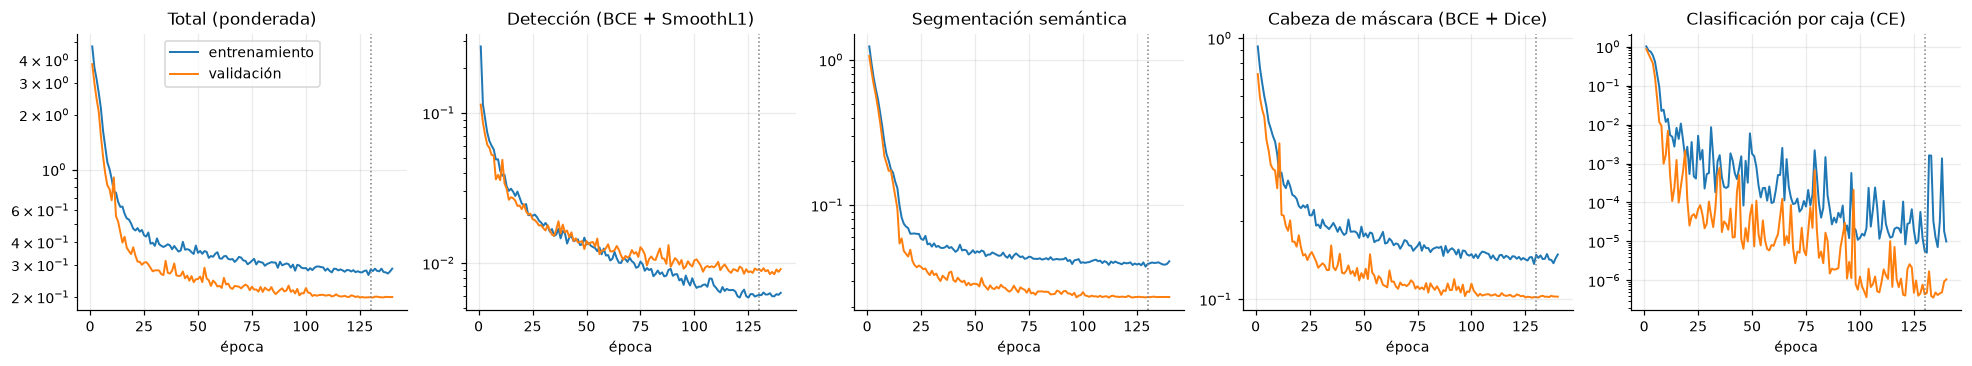

In [3]:
panel = [("Total (ponderada)", "loss"), ("Detección (BCE + SmoothL1)", ("obj", "box")), ("Segmentación semántica", "seg"),
         ("Cabeza de máscara (BCE + Dice)", "mask"), ("Clasificación por caja (CE)", "anat")]
fig, ax = plt.subplots(1, 5, figsize=(18, 3.4))
for a, (title, k) in zip(ax, panel):
    for split, color in (("train", "tab:blue"), ("val", "tab:orange")):
        y = h[f"{split}_{k[0]}"] + h[f"{split}_{k[1]}"] if isinstance(k, tuple) else h[f"{split}_{k}"]
        a.plot(h.epoch, y, color=color, lw=1.3, label="entrenamiento" if split == "train" else "validación")
    a.axvline(metrics["epoch"], color="grey", ls=":", lw=1)
    a.set_yscale("log"); a.set_title(title); a.set_xlabel("época")
ax[0].legend()
plt.tight_layout(); plt.show()

- **Todas las pérdidas bajan** en entrenamiento y en validación.
- **Detección:** desde la época ~60 la pérdida de validación (0,008) queda por encima de la de entrenamiento (0,005):
  sobreajuste leve; el mAP de validación sigue subiendo.
- **Clasificación por caja:** llega a ~1e-5. Es la tarea más fácil.
- **La pérdida de validación queda por debajo de la de entrenamiento** (total, semántica y máscara) porque el
  entrenamiento usa aumento de datos y la validación no. Sin aumento, las métricas de entrenamiento y de validación
  coinciden (Dice semántico 0,967 y 0,966). El notebook 05 lo comprueba.

### Curvas de métricas: entrenamiento frente a validación

Una métrica por cabeza, cada 5 épocas: en 15 CT fijos de entrenamiento (sin aumento) y en los 15 de validación. La
última gráfica separa el Dice de la semántica por hueso (validación).

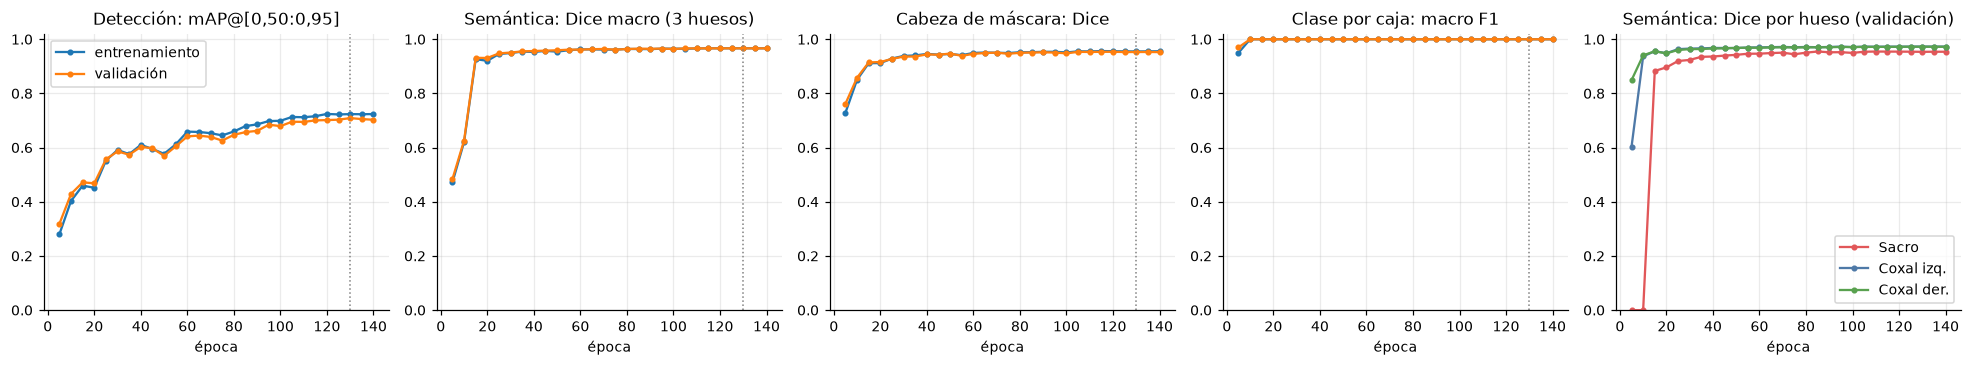

,val_mAP50_95,val_dice_sacro,val_dice_izq,val_dice_der,val_dice_mask,val_macro_f1,val_score
epoch,,,,,,,
5,0.318,0.000,0.603,0.849,0.762,0.97,0.634
10,0.429,0.000,0.937,0.941,0.858,1.00,0.728
15,0.472,0.883,0.956,0.956,0.915,1.00,0.829
30,0.586,0.924,0.966,0.964,0.936,1.00,0.868
60,0.641,0.947,0.970,0.969,0.946,1.00,0.887
130,0.709,0.954,0.973,0.972,0.953,1.00,0.907
140,0.703,0.954,0.973,0.972,0.953,1.00,0.906


In [4]:
panel = [("Detección: mAP@[0,50:0,95]", "mAP50_95"), ("Semántica: Dice macro (3 huesos)", "dice_sem"),
         ("Cabeza de máscara: Dice", "dice_mask"), ("Clase por caja: macro F1", "macro_f1")]
fig, ax = plt.subplots(1, 5, figsize=(18, 3.4))
for a, (title, k) in zip(ax, panel):
    a.plot(v.epoch, v[f"train_{k}"], "o-", ms=3, color="tab:blue", label="entrenamiento")
    a.plot(v.epoch, v[f"val_{k}"], "o-", ms=3, color="tab:orange", label="validación")
    a.axvline(metrics["epoch"], color="grey", ls=":", lw=1)
    a.set_title(title); a.set_xlabel("época"); a.set_ylim(0, 1.02)
for (k, nombre), color in zip((("sacro", "Sacro"), ("izq", "Coxal izq."), ("der", "Coxal der.")), COLOR_HUESO):
    ax[4].plot(v.epoch, v[f"val_dice_{k}"], "o-", ms=3, color=color, label=nombre)
ax[4].set_title("Semántica: Dice por hueso (validación)"); ax[4].set_xlabel("época"); ax[4].set_ylim(0, 1.02)
ax[0].legend(); ax[4].legend()
plt.tight_layout(); plt.show()
v[["epoch", "val_mAP50_95", "val_dice_sacro", "val_dice_izq", "val_dice_der", "val_dice_mask", "val_macro_f1",
   "val_score"]].iloc[[0, 1, 2, 5, 11, len(v) - 3, len(v) - 1]].set_index("epoch").round(3)

- **El sacro arranca tarde:** Dice 0 en las épocas 5 y 10, 0,883 en la 15 y 0,954 al final. Los coxales aprenden desde
  la época 5-10.
- **Sin brecha entre entrenamiento y validación** en ninguna cabeza.
- **Detección:** el mAP@[0,50:0,95] sube hasta el final (0,709 en la época 130, la elegida).
- **Cabeza de máscara:** Dice 0,86 en la época 10 y 0,953 al final.
- **Clase por caja:** F1 = 1 desde la época 10.

### γ: cuánto usa la red la atención

Cada capa con atención calcula `y = x + γ · CBAM(x)`. γ empieza en 0 y la red lo aprende: cerca de 0 al final = la red
casi no usó esa atención; |γ| grande = la usa (el signo dice si suma o resta lo que resalta el CBAM). Hay CBAM en el
bloque 4 del encoder (`enc4`), en la primera capa del decoder (`dec_p3`) y en la cabeza de detección (`head_axial`).
La comparación con SE está en la sección 8.

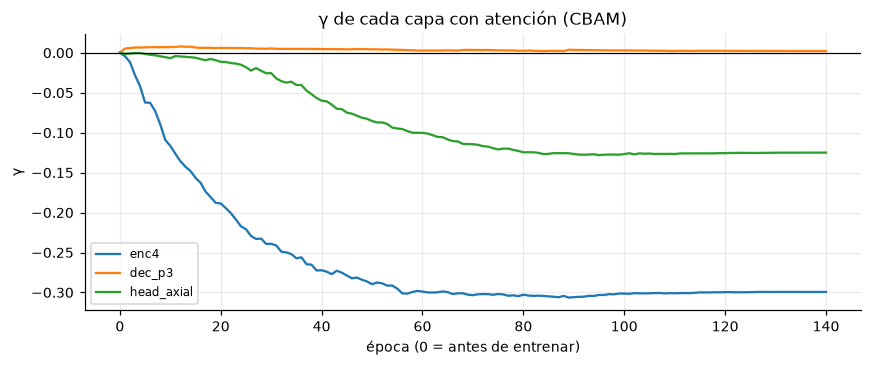

epoch,0,70,140
gamma_enc4,0.0,-0.303,-0.299
gamma_dec_p3,0.0,0.004,0.002
gamma_head_axial,0.0,-0.114,-0.125


In [5]:
gcols = [c for c in hist.columns if c.startswith("gamma_")]
g = hist[["epoch", *gcols]].assign(epoch=lambda d: d.epoch + 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
for c in gcols:
    ax.plot(g.epoch, g[c], lw=1.5, label=c.removeprefix("gamma_"))
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("época (0 = antes de entrenar)"); ax.set_ylabel("γ"); ax.set_title("γ de cada capa con atención (CBAM)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
g.set_index("epoch").iloc[[0, len(g) // 2, -1]].T.round(3)

- **enc4 (γ = −0,30):** la red sí usa la atención del último bloque del encoder; el signo negativo indica que resta lo
  que resalta el CBAM.
- **Cabeza de detección (γ = −0,13):** la usa, menos.
- **dec_p3 (γ = 0,002):** la red **no usa** el CBAM que se agregó en la primera capa del decoder. Con SE esa misma capa
  sí se usa (sección 8).

## 2. Resultados en test frente a la rúbrica

Las salidas de segmentación aparecen por separado, cada una medida como la mide `evaluate`: la semántica en el cubo
(1,56 mm), y la cabeza de máscara y la fusión de las dos a doble resolución en el plano (0,78 mm). La comparación entre las dos en la misma
rejilla está en las secciones 4 y 5.

In [6]:
def tabla_rubrica(m):
    t = m["splits"]["test"]
    margin = m["refine_margin_from_val"]
    raw, ref = t["detection"]["raw"]["all"], t["detection"][f"m{margin}"]["all"]
    ce, sb, sm = t["classification_roi_end_to_end"], t["segmentation_bones"]["promedio"], t["segmentation_bones_mask"]["promedio"]
    filas = [("Clasificación (hueso de cada caja predicha)", "F1 macro", ce["macro_f1"], 0.85),
             ("Clasificación (hueso de cada caja predicha)", "AUC macro", ce["macro_auc"], 0.85),
             ("Detección (cajas axiales)", "IoU promedio", raw["mIoU"], 0.65),
             ("Detección (cajas axiales)", "mAP@0,50", raw["mAP50"], 0.65),
             ("Detección (cajas axiales)", "mAP@[0,50:0,95]", raw["mAP50_95"], 0.40),
             (f"Detección + ajuste a la segmentación ({margin} px)", "mAP@[0,50:0,95]", ref["mAP50_95"], 0.40),
             ("Segmentación semántica (macro de los 3 huesos)", "Dice", sb["dice"], 0.85),
             ("Segmentación semántica (macro de los 3 huesos)", "IoU", sb["iou"], 0.70),
             ("Cabeza de máscara (macro de los 3 huesos)", "Dice", sm["dice"], 0.85),
             ("Cabeza de máscara (macro de los 3 huesos)", "IoU", sm["iou"], 0.70)]
    if "segmentation_bones_fusion" in t:                 # fusión de las dos salidas (sección 5)
        sf = t["segmentation_bones_fusion"]["promedio"]
        filas += [("Fusión de las dos salidas (macro de los 3 huesos)", "Dice", sf["dice"], 0.85),
                  ("Fusión de las dos salidas (macro de los 3 huesos)", "IoU", sf["iou"], 0.70)]
    return pd.DataFrame(filas, columns=["tarea", "métrica", "test", "objetivo"])


tabla = tabla_rubrica(metrics)
tabla["cumple"] = np.where(tabla.test >= tabla.objetivo, "sí", "no")
tabla.style.format({"test": "{:.3f}", "objetivo": "≥ {:.2f}"}).hide(axis="index")

tarea,métrica,test,objetivo,cumple
Clasificación (hueso de cada caja predicha),F1 macro,1.000,≥ 0.85,sí
Clasificación (hueso de cada caja predicha),AUC macro,1.000,≥ 0.85,sí
Detección (cajas axiales),IoU promedio,0.861,≥ 0.65,sí
Detección (cajas axiales),"mAP@0,50",0.938,≥ 0.65,sí
Detección (cajas axiales),"mAP@[0,50:0,95]",0.686,≥ 0.40,sí
Detección + ajuste a la segmentación (2 px),"mAP@[0,50:0,95]",0.816,≥ 0.40,sí
Segmentación semántica (macro de los 3 huesos),Dice,0.952,≥ 0.85,sí
Segmentación semántica (macro de los 3 huesos),IoU,0.909,≥ 0.70,sí
Cabeza de máscara (macro de los 3 huesos),Dice,0.950,≥ 0.85,sí
Cabeza de máscara (macro de los 3 huesos),IoU,0.905,≥ 0.70,sí


- **Cumple todos los objetivos de la rúbrica en test.**
- **Detección:** mAP@0,50 0,938, mAP@[0,50:0,95] 0,686 e IoU 0,861. Ajustando cada caja al hueso segmentado, el
  mAP@[0,50:0,95] sube a 0,818.
- **Segmentación semántica:** Dice macro 0,952 e IoU 0,909.
- **Cabeza de máscara:** Dice macro 0,950 e IoU 0,906, medida a 0,78 mm.
- **Fusión de las dos salidas** (sección 5): Dice macro 0,950 e IoU 0,906, con el mejor borde (HD95 1,9 mm).
- **Clasificación:** F1 y AUC = 1 sobre las cajas predichas.
- El Dice de «segmentación de fragmento» de la rúbrica se mide por hueso (sacro, coxal izquierdo, coxal derecho).

## 3. Segmentación semántica por hueso

Dice, IoU, HD95 y ASSD de cada máscara de la cabeza semántica y su macro (promedio de los tres huesos), y el Dice de la
pelvis completa (hueso contra fondo). HD95 y ASSD en mm, como en el challenge PENGWIN (extensión opcional de la rúbrica).

In [7]:
filas = []
for split in ("val", "test"):
    sbs = metrics["splits"][split]["segmentation_bones"]
    for k, nombre in HUESOS.items():
        filas.append({"split": split, "hueso": nombre, **{m.upper() if m in ("hd95", "assd") else m.capitalize(): sbs[k][m]
                                                          for m in ("dice", "iou", "hd95", "assd")}})
    pel = metrics["splits"][split]["segmentation_pelvis"]
    filas.append({"split": split, "hueso": "Pelvis (hueso / fondo)", "Dice": pel["dice"], "Iou": pel["iou"]})
pd.DataFrame(filas).rename(columns={"Iou": "IoU", "HD95": "HD95 (mm)", "ASSD": "ASSD (mm)"}).set_index(
    ["split", "hueso"]).round(3)

Dice    IoU  HD95 (mm)  ASSD (mm)
split hueso                                                     
val   Sacro                   0.935  0.879      4.158      0.753
      Coxal izquierdo         0.965  0.933      1.649      0.417
      Coxal derecho           0.965  0.933      1.606      0.412
      Macro (3 huesos)        0.955  0.915      2.471      0.527
      Pelvis (hueso / fondo)  0.958  0.919        NaN        NaN
test  Sacro                   0.937  0.883      2.834      0.658
      Coxal izquierdo         0.958  0.919      1.829      0.492
      Coxal derecho           0.961  0.925      1.692      0.455
      Macro (3 huesos)        0.952  0.909      2.119      0.535
      Pelvis (hueso / fondo)  0.954  0.913        NaN        NaN

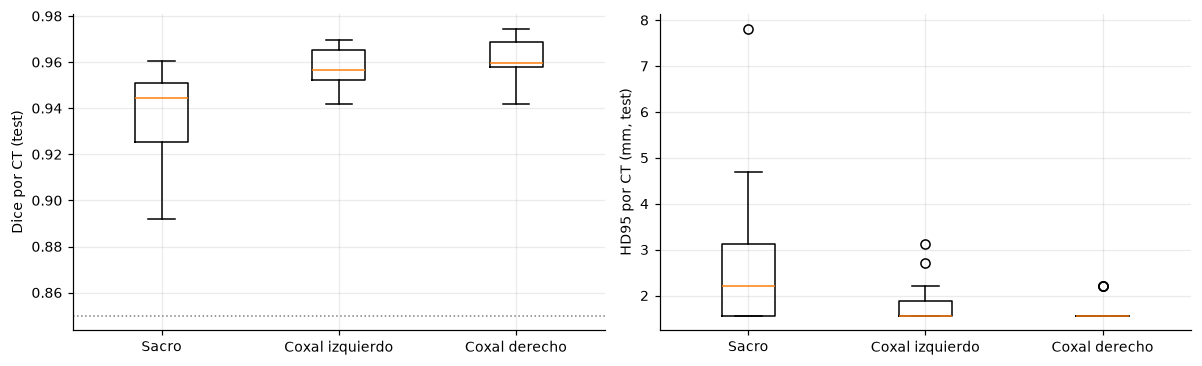

Sacro: mínimo 0.892 en el CT 034 | CT con algún hueso bajo 0,85: 0


In [8]:
cases = R["CBAM"]["cases"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
data = [cases[f"huesos_{k}_dice"].dropna() for k in list(HUESOS)[:3]]
ax[0].boxplot(data, tick_labels=[HUESOS[k] for k in list(HUESOS)[:3]]); ax[0].set_ylabel("Dice por CT (test)")
ax[0].axhline(0.85, color="grey", ls=":", lw=1)
data = [cases[f"huesos_{k}_hd95"].dropna() for k in list(HUESOS)[:3]]
ax[1].boxplot(data, tick_labels=[HUESOS[k] for k in list(HUESOS)[:3]]); ax[1].set_ylabel("HD95 por CT (mm, test)")
plt.tight_layout(); plt.show()
print("Sacro: mínimo", cases.huesos_sacro_dice.min().round(3), "en el CT", cases.case_id[cases.huesos_sacro_dice.idxmin()],
      "| CT con algún hueso bajo 0,85:", int((cases[[f"huesos_{k}_dice" for k in list(HUESOS)[:3]]] < 0.85).any(axis=1).sum()))

- **Coxales:** Dice 0,958 y 0,961, HD95 ~1,7 mm (un vóxel del cubo mide 1,56 mm) y ASSD ~0,5 mm.
- **Sacro:** el más difícil (Dice 0,937, HD95 2,8 mm); no baja de 0,85 en ningún CT de test (mínimo 0,892, CT 034).
- **Validación y test se parecen** (macro 0,955 y 0,952).

## 4. La cabeza de máscara

### 4.1 Cuál es su salida

Es una cabeza tipo Mask R-CNN que trabaja **caja por caja y corte por corte**:

1. **Entrada:** cada caja axial predicha con puntaje ≥ 0,5. Dentro de la caja se recortan con ROI Align las
   características P2 y P1 del corte (48 × 48) y el CT a doble resolución (96 × 96, dos canales).
2. **Rama de clase:** del vector promedio de la caja sale el hueso (sacro, coxal izquierdo o coxal derecho). Es la cabeza
   de clasificación del modelo.
3. **Rama de máscara:** 2 conv → deconvolución ×2 → se concatena el CT → 2 conv → **tres máscaras de 96 × 96**, una por
   hueso. Se usa la del hueso que dijo la rama de clase.
4. **Salida final:** cada máscara se pega en su caja, en el corte a 512 × 512 (0,78 mm por píxel). Si dos cajas se
   solapan, gana la de mayor probabilidad. El resultado es un volumen de etiquetas de 256 × 512 × 512: 0 fondo, 1 sacro,
   2 coxal izquierdo, 3 coxal derecho.

La figura muestra esa salida en un corte: a la izquierda las cajas con su clase y puntaje; a la derecha, lo que la
cabeza devuelve dentro de cada caja (color = hueso predicho) y el borde real en blanco.

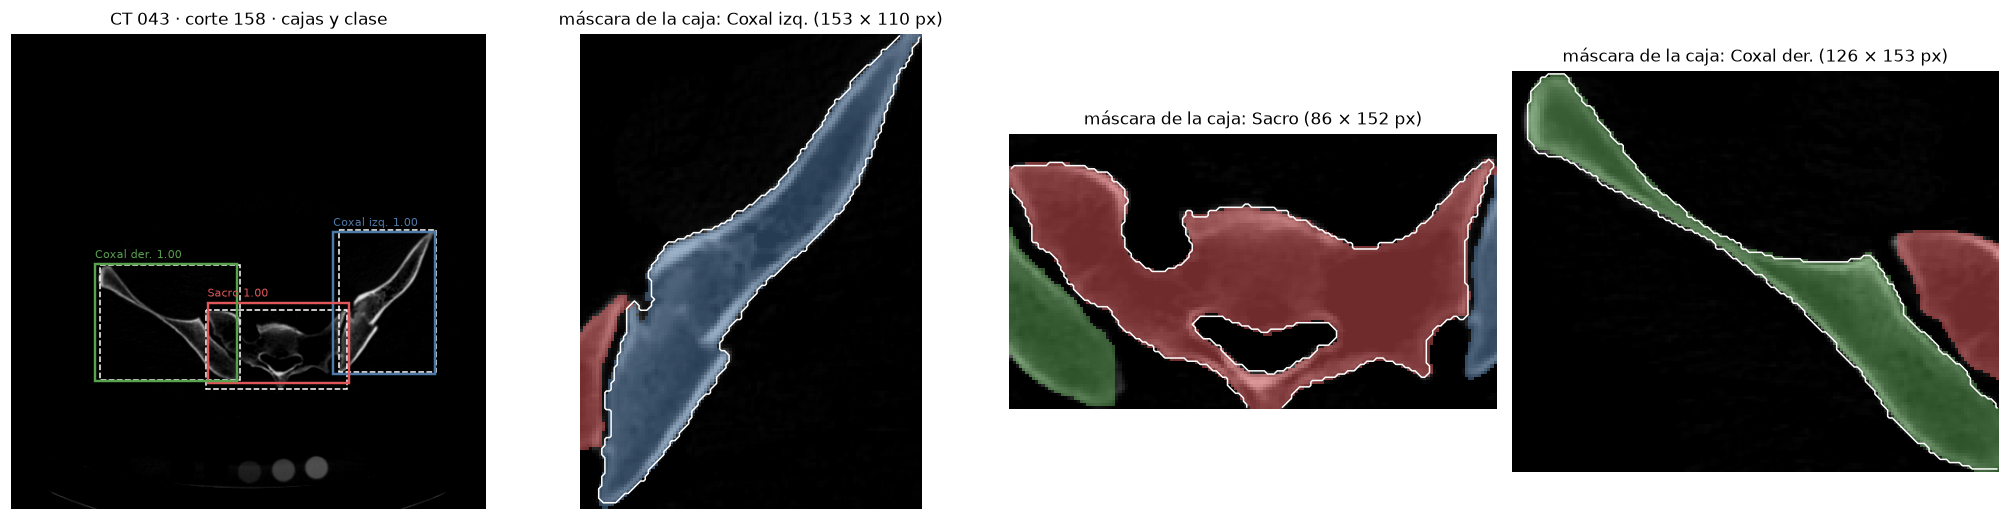

In [9]:
def cargar_ejemplo(run, cid):
    # Salidas guardadas por scripts/comparar_cabezas.py + CT y máscara real a doble resolución (caché).
    z = np.load(config.DETECTION_DIR / run / "eval" / "examples_heads" / f"{cid}.npz")
    codes = np.load(config.M3D_HIRES_DIR / f"{cid}_msk.npy")
    return {"cid": cid, "img": np.load(config.M3D_HIRES_DIR / f"{cid}_img.npy", mmap_mode="r"),
            "gt": np.where(codes > 0, (codes.astype(np.int16) - 1) // 10 + 1, 0).astype(np.uint8),
            "sem": z["sem"].repeat(F_HR, 1).repeat(F_HR, 2), "mask": z["mask"], "boxes": z["boxes"], "scores": z["scores"],
            "cls": z["cls"], "sd_sem": z["slice_dice_sem"], "sd_mask": z["slice_dice_mask"], "papel": str(z["papel"])}


def dibujar_cajas(ax, e, k):
    # Corte axial k: cajas reales (blanco, discontinuas) y predichas (color = hueso que dice la rama de clase).
    ax.imshow(e["img"][k], cmap="gray", vmin=0, vmax=255)
    for c in (1, 2, 3):
        ys, xs = np.nonzero(e["gt"][k] == c)
        if len(ys) >= config.MIN_REGION_PX * F_HR ** 2:
            ax.add_patch(patches.Rectangle((xs.min(), ys.min()), np.ptp(xs) + 1, np.ptp(ys) + 1, fill=False, ec="white",
                                           ls="--", lw=1))
    for (j, x0, y0, x1, y1), s, c in zip(e["boxes"], e["scores"], e["cls"]):
        if int(j) == k:
            ax.add_patch(patches.Rectangle((x0 * F_HR, y0 * F_HR), (x1 - x0) * F_HR, (y1 - y0) * F_HR, fill=False,
                                           ec=COLOR_HUESO[c], lw=1.6))
            ax.text(x0 * F_HR, y0 * F_HR - 4, f"{config.REGION_LABELS[config.REGION_NAMES[c]]} {s:.2f}",
                    color=COLOR_HUESO[c], fontsize=7, va="bottom")
    ax.axis("off"); ax.grid(False)


def elegir_corte(e, papel):
    area = (e["gt"] > 0).sum((1, 2))
    media, dif = (e["sd_sem"] + e["sd_mask"]) / 2, e["sd_mask"] - e["sd_sem"]
    crit = {"mejor": area.astype(float), "peor": -media, "gana_mascara": dif, "gana_semantica": -dif}[papel]
    return int(np.where(area >= 0.25 * area.max(), crit, -np.inf).argmax())


def recorte(labs, margen=24):
    # Caja que envuelve el hueso (real o predicho) de un corte, con margen.
    ys, xs = np.nonzero(np.any([l > 0 for l in labs], axis=0))
    H, W = labs[0].shape
    return np.s_[max(ys.min() - margen, 0):min(ys.max() + margen, H), max(xs.min() - margen, 0):min(xs.max() + margen, W)]


def dibujar_mascara(ax, img, lab, gt, titulo, aspect=1):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, aspect=aspect)
    ax.imshow(np.ma.masked_equal(lab, 0) - 1, cmap=COLORES, vmin=0, vmax=2, alpha=0.5, interpolation="nearest", aspect=aspect)
    if gt is not None:
        ax.imshow(np.ma.masked_equal((lab != gt).astype(np.uint8), 0), cmap=ERROR, alpha=0.95, interpolation="nearest",
                  aspect=aspect)
    ax.set_title(titulo, fontsize=9); ax.axis("off"); ax.grid(False)


PAPELES = {}
for q in sorted((EVAL / "examples_heads").glob("*.npz")):
    for p in str(np.load(q)["papel"]).split(","):
        if p:
            PAPELES[p] = q.stem
e = cargar_ejemplo(RUNS["CBAM"], PAPELES["mejor"])
k = int((e["gt"] > 0).sum((1, 2)).argmax())
cajas = [(b, s, c) for b, s, c in zip(e["boxes"], e["scores"], e["cls"]) if int(b[0]) == k][:3]
fig, axes = plt.subplots(1, 1 + len(cajas), figsize=(4.6 * (1 + len(cajas)), 4.8))
dibujar_cajas(axes[0], e, k)
axes[0].set_title(f"CT {e['cid']} · corte {k} · cajas y clase")
for a, ((_, x0, y0, x1, y1), s, c) in zip(axes[1:], cajas):
    a0, b0, a1, b1 = [int(round(t * F_HR)) for t in (x0, y0, x1, y1)]
    rec = np.s_[max(b0, 0):b1, max(a0, 0):a1]
    a.imshow(e["img"][k][rec], cmap="gray", vmin=0, vmax=255)
    a.imshow(np.ma.masked_equal(e["mask"][k][rec], 0) - 1, cmap=COLORES, vmin=0, vmax=2, alpha=0.5, interpolation="nearest")
    a.contour(e["gt"][k][rec] == c + 1, levels=[0.5], colors="white", linewidths=1)
    a.set_title(f"máscara de la caja: {config.REGION_LABELS[config.REGION_NAMES[c]]} ({b1 - b0} × {a1 - a0} px)")
    a.axis("off"); a.grid(False)
plt.tight_layout(); plt.show()

### 4.2 La rama de clase (clasificación por caja)

Cada caja predicha de test se compara con la caja real de su corte (IoU ≥ 0,5). Matriz de confusión de la rama de clase
sobre las cajas con pareja, y qué pasa con las cajas sin pareja (cajas de más: la caja real no existe o el IoU es bajo).

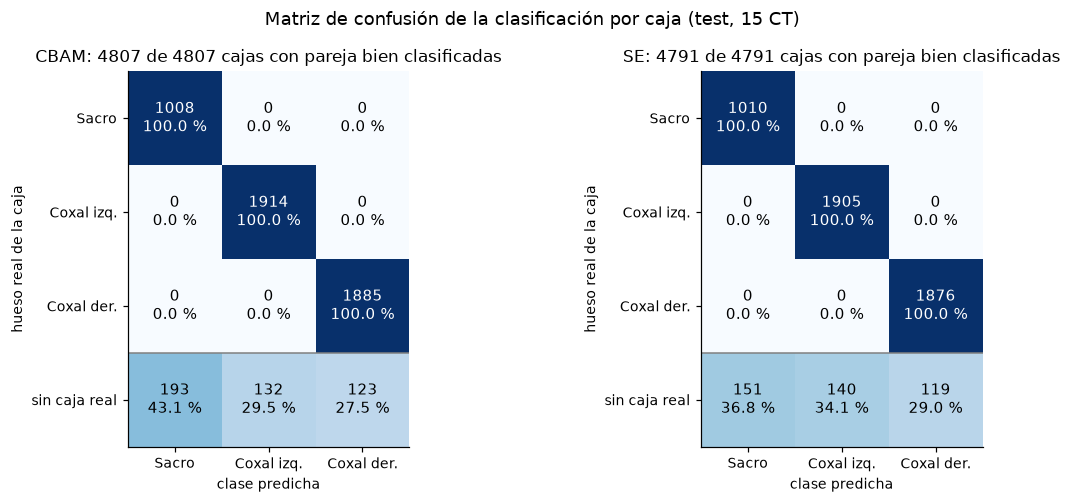

Cajas predichas en test: 5255 | sin pareja real: 448 (8.5 %), puntaje mediano 0.86 frente a 1.00 de las que tienen pareja
F1 macro: 1.0 | AUC macro: 1.0 | probabilidad mínima de la clase elegida: 0.515


In [10]:
t = metrics["splits"]["test"]
nombres = [config.REGION_LABELS[r] for r in config.REGION_NAMES]
rois = R["CBAM"]["rois"]

# Matriz de confusión de la clasificación (test): filas = hueso real de la caja, columnas = clase predicha.
# La última fila son las cajas predichas sin pareja real (cajas de más): no tienen clase real.
filas = nombres + ["sin caja real"]
fig, axes = plt.subplots(1, len(R), figsize=(5.6 * len(R), 4.6), squeeze=False)
for ax, (nombre, r) in zip(axes[0], R.items()):
    rr = r["rois"]
    cm = np.array([[int(((rr.class_true == i) & (rr.class_pred == j)).sum()) for j in range(3)] for i in (0, 1, 2, -1)])
    pct = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{100 * pct[i, j]:.1f} %", ha="center", va="center", fontsize=10,
                    color="white" if pct[i, j] > 0.5 else "black")
    ax.axhline(2.5, color="gray", lw=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(nombres)
    ax.set_yticks(range(4)); ax.set_yticklabels(filas)
    ax.set_xlabel("clase predicha"); ax.set_ylabel("hueso real de la caja")
    ok = rr[rr.class_true >= 0]
    ax.set_title(f"{nombre}: {int((ok.class_true == ok.class_pred).sum())} de {len(ok)} cajas con pareja bien clasificadas")
    ax.grid(False)
fig.suptitle("Matriz de confusión de la clasificación por caja (test, 15 CT)", fontsize=12)
plt.tight_layout()
FIG = config.PROJECT_ROOT / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG / "matriz_confusion_clasificacion.png", dpi=150, bbox_inches="tight")
plt.show()
sin = rois[rois.class_true < 0]
print(f"Cajas predichas en test: {len(rois)} | sin pareja real: {len(sin)} ({100 * len(sin) / len(rois):.1f} %), "
      f"puntaje mediano {sin.score.median():.2f} frente a {rois[rois.class_true >= 0].score.median():.2f} de las que tienen pareja")
print("F1 macro:", t["classification_roi_end_to_end"]["macro_f1"], "| AUC macro:", t["classification_roi_end_to_end"]["macro_auc"],
      "| probabilidad mínima de la clase elegida:", rois[["prob_0", "prob_1", "prob_2"]].max(axis=1).min().round(3))

- **Ninguna caja con pareja se clasifica mal** (4.807 de 4.807).
- **Cajas sin pareja (8,5 %):** cajas de más o mal ajustadas, casi dos tercios en los cortes de los extremos de la
  pelvis, con menor puntaje (mediana 0,86 frente a 1,00). También reciben clase y máscara: son la fuente de los falsos
  positivos de la cabeza de máscara.
- F1 = 1 indica que la tarea es fácil: el hueso de una caja se distingue por su posición y su forma.

### 4.3 ¿Ayuda a la segmentación?

La cabeza de máscara es una salida **paralela**: su pérdida no llega al backbone y no cambia la máscara semántica. La
pregunta es si su máscara es mejor.

`evaluate` mide cada cabeza en su rejilla (1,56 mm y 0,78 mm), así que los números de la sección 2 no se pueden
comparar entre sí. Aquí las dos se miden contra **la misma máscara real, la de 0,78 mm** (la semántica se lleva a
512 × 512 por vecino más cercano).

In [11]:
heads = R["CBAM"]["heads"]
t = heads.groupby(["hueso", "salida"])[["dice", "iou", "hd95", "assd"]].mean().unstack("salida")
t = t.reindex(index=list(HUESOS)).rename(index=HUESOS)
t = t.reindex(columns=pd.MultiIndex.from_product([["dice", "iou", "hd95", "assd"], list(SALIDAS)])).rename(
    columns={"dice": "Dice", "iou": "IoU", "hd95": "HD95 (mm)", "assd": "ASSD (mm)", **SALIDAS})
t.round(3)

Dice                                IoU  \
                 Cabeza semántica Cabeza de máscara Cabeza semántica   
hueso                                                                  
Sacro                       0.929             0.930            0.867   
Coxal izquierdo             0.948             0.958            0.902   
Coxal derecho               0.952             0.962            0.908   
Macro (3 huesos)            0.943             0.950            0.892   

                                          HD95 (mm)                    \
                 Cabeza de máscara Cabeza semántica Cabeza de máscara   
hueso                                                                   
Sacro                        0.870            2.637             3.339   
Coxal izquierdo              0.920            1.773             1.637   
Coxal derecho                0.926            1.641             1.404   
Macro (3 huesos)             0.905            2.017             2.126   

                        ASSD (mm)                    
                 Cabeza semántica Cabeza de máscara  
hueso                                                
Sacro                       0.580             0.662  
Coxal izquierdo             0.472             0.517  
Coxal derecho               0.439             0.393  
Macro (3 huesos)            0.497             0.524

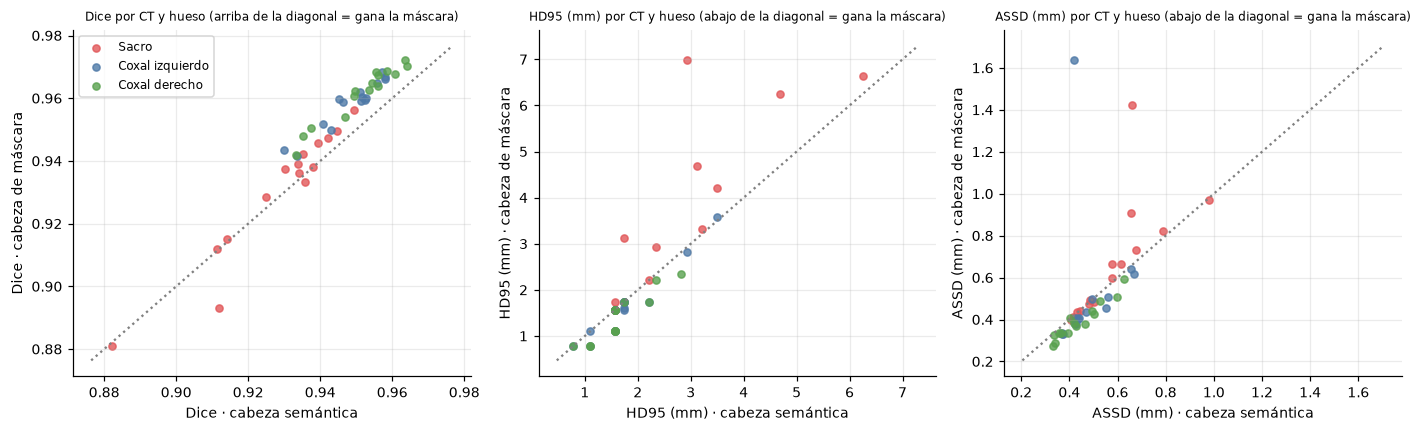

In [12]:
def pareado(df, a, b, col):
    # Por CT y hueso: valor de la salida `a` y de la `b`; en cuántos CT gana `b` y p de Wilcoxon pareado.
    filas = []
    for hueso, nombre in HUESOS.items():
        p = df[df.hueso == hueso].pivot(index="case_id", columns="salida", values=col)
        gana = (p[b] > p[a]) if col in ("dice", "iou") else (p[b] < p[a])
        filas.append({"hueso": nombre, "métrica": col, a: p[a].mean(), b: p[b].mean(), "CT donde gana la máscara": f"{int(gana.sum())} de {len(p)}",
                      "p (Wilcoxon pareado)": wilcoxon(p[a], p[b]).pvalue})
    return filas


comp = pd.DataFrame(sum((pareado(heads, "semantica", "mascara", c) for c in ("dice", "hd95", "assd")), []))
comp = comp.rename(columns=SALIDAS).set_index(["métrica", "hueso"])
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (col, titulo) in zip(ax, (("dice", "Dice"), ("hd95", "HD95 (mm)"), ("assd", "ASSD (mm)"))):
    for hueso, color in zip(list(HUESOS)[:3], COLOR_HUESO):
        p = heads[heads.hueso == hueso].pivot(index="case_id", columns="salida", values=col)
        a.scatter(p.semantica, p.mascara, color=color, alpha=0.8, s=22, label=HUESOS[hueso])
    lo, hi = a.get_xlim()[0], max(a.get_xlim()[1], a.get_ylim()[1])
    lo = min(lo, a.get_ylim()[0])
    a.plot([lo, hi], [lo, hi], color="grey", ls=":")
    a.set_xlabel(f"{titulo} · cabeza semántica"); a.set_ylabel(f"{titulo} · cabeza de máscara")
    a.set_title(f"{titulo} por CT y hueso ({'arriba' if col == 'dice' else 'abajo'} de la diagonal = gana la máscara)", fontsize=8)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
comp.style.format({SALIDAS["semantica"]: "{:.3f}", SALIDAS["mascara"]: "{:.3f}", "p (Wilcoxon pareado)": "{:.4f}"})

**Fragmentos pequeños.** Para cada fragmento conminuto real de test: qué fracción de sus vóxeles marca cada salida con
el hueso correcto (recall del fragmento), según su tamaño.

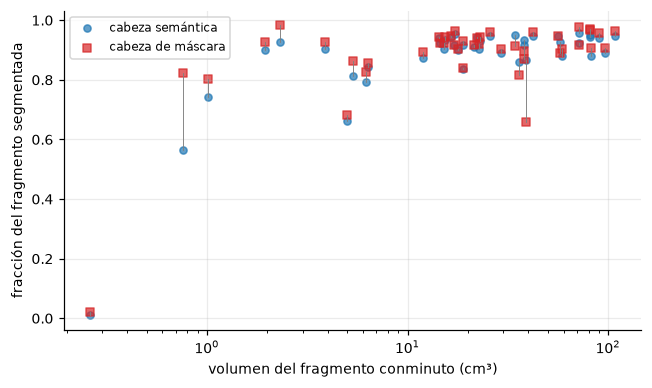

,fragmentos,recall medio · semántica,recall medio · máscara,fragmentos donde gana la máscara
tamaño,,,,
< 10 cm³,10,0.716,0.772,10
10-30 cm³,17,0.916,0.924,16
> 30 cm³,17,0.921,0.907,10


In [13]:
fr = R["CBAM"]["frags"]
fr = fr[~fr.principal].assign(cm3=lambda d: d.volumen_mm3 / 1000)
fr["tamaño"] = pd.cut(fr.cm3, [0, 10, 30, 1e9], labels=["< 10 cm³", "10-30 cm³", "> 30 cm³"])
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(fr.cm3, fr.recall_semantica, s=22, color="tab:blue", alpha=0.7, label="cabeza semántica")
ax.scatter(fr.cm3, fr.recall_mascara, s=22, color="tab:red", alpha=0.7, marker="s", label="cabeza de máscara")
for _, r in fr.iterrows():
    ax.plot([r.cm3, r.cm3], [r.recall_semantica, r.recall_mascara], color="grey", lw=0.6)
ax.set_xscale("log"); ax.set_xlabel("volumen del fragmento conminuto (cm³)"); ax.set_ylabel("fracción del fragmento segmentada")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
res = fr.groupby("tamaño", observed=True).agg(fragmentos=("cm3", "size"), semantica=("recall_semantica", "mean"),
                                              mascara=("recall_mascara", "mean"),
                                              gana_mascara=("recall_mascara", lambda s: int((s > fr.loc[s.index, "recall_semantica"]).sum())))
res.rename(columns={"semantica": "recall medio · semántica", "mascara": "recall medio · máscara",
                    "gana_mascara": "fragmentos donde gana la máscara"}).round(3)

**Dependencia de la detección.** La cabeza de máscara solo existe donde hay una caja con puntaje ≥ 0,5. Cortes con
hueso real donde cada salida queda vacía, y cuánto coinciden las dos salidas entre sí.

In [14]:
hc = R["CBAM"]["heads_cases"]
print(f"Cortes con hueso real en test: {hc.cortes_con_hueso.sum()} | vacíos en la semántica: {hc.cortes_vacios_semantica.sum()} | "
      f"vacíos en la cabeza de máscara: {hc.cortes_vacios_mascara.sum()} | Dice entre las dos salidas: {hc.dice_entre_cabezas.mean():.3f}")
d = pd.DataFrame({s: {"semántica": metrics["splits"][s]["separation_distance"]["mae_mm"],
                      "máscara": metrics["splits"][s]["separation_distance_mask"]["mae_mm"],
                      "semántica (> 2 mm)": metrics["splits"][s]["separation_distance"]["mae_mm_gt_2mm"],
                      "máscara (> 2 mm)": metrics["splits"][s]["separation_distance_mask"]["mae_mm_gt_2mm"],
                      "unidos al principal · semántica": metrics["splits"][s]["separation_distance"]["merged_with_main"],
                      "unidos al principal · máscara": metrics["splits"][s]["separation_distance_mask"]["merged_with_main"]}
                  for s in ("val", "test")}).T
d.index.name = "error medio de la distancia de separación (mm)"
d.round(2)

Cortes con hueso real en test: 2056 | vacíos en la semántica: 3 | vacíos en la cabeza de máscara: 2 | Dice entre las dos salidas: 0.958


,semántica,máscara,semántica (> 2 mm),máscara (> 2 mm),unidos al principal · semántica,unidos al principal · máscara
error medio de la distancia de separación (mm),,,,,,
val,4.17,3.87,31.23,28.53,0.94,0.94
test,1.81,1.78,9.67,11.21,0.93,0.91


**La máscara de la cabeza de máscara es algo mejor que la semántica** en la misma rejilla. La mejora está en los
coxales y en los fragmentos pequeños; en el sacro no gana.

- **Dice macro:** 0,950 frente a 0,943; gana en 14 de 15 CT (p = 0,0001).
- **Coxales:** gana en los 15 CT (+0,010 de Dice) y baja el HD95 (1,40 frente a 1,64 mm en el coxal derecho).
- **Fragmentos pequeños (< 10 cm³):** recupera 0,77 de cada fragmento frente a 0,72.
- **Sacro:** el Dice empata (0,930 frente a 0,929) y el HD95 empeora en los 15 CT (3,3 frente a 2,6 mm).
- **Distancia de separación:** igual que con la semántica (1,78 frente a 1,81 mm).
- **Límites:** depende de la caja (sin caja no hay máscara) y trabaja corte por corte, sin usar los cortes vecinos.

## 5. Semántica, cabeza de máscara y fusión

El modelo da dos máscaras de cada hueso. La **fusión** es un postproceso (`model3d.fuse_heads`, sin reentrenar) que las
une en una sola:

- **Coxales:** los de la cabeza de máscara.
- **Sacro:** el de la semántica, más lo que la cabeza de máscara marca como sacro donde todavía es fondo.

Las tres salidas se miden contra la misma máscara real, la de 0,78 mm.

### 5.1 Cómo se eligió la fusión

Se probaron tres modos de `fuse_heads` y se eligió en validación, por Dice macro; test
solo se mira después.
- `huesos`: coxales de la cabeza de máscara, sacro de la semántica.
- `union_sacro`: lo anterior más el sacro de la cabeza de máscara donde aún es fondo.
- `relleno`: lo anterior y, en los cortes donde la cabeza de máscara no marca un coxal, ese coxal sale de la semántica.

In [15]:
filas = {}
for split in ("val", "test"):
    hh = pd.read_csv(EVAL / f"heads_{split}.csv", dtype={"case_id": str})
    hh = hh[hh.hueso == "promedio"].groupby("salida")[["dice", "hd95", "assd"]].mean()
    filas[split] = hh.reindex(["semantica", "mascara", "fusion", "fusion_huesos", "fusion_union_sacro", "fusion_relleno"])
t = pd.concat(filas, axis=1).rename(columns={"dice": "Dice macro", "hd95": "HD95 (mm)", "assd": "ASSD (mm)"})
print("Modo elegido en validación (config.M3D_FUSION_MODE):", config.M3D_FUSION_MODE)
t.round(4)

Modo elegido en validación (config.M3D_FUSION_MODE): union_sacro


val                           test            \
                   Dice macro HD95 (mm) ASSD (mm) Dice macro HD95 (mm)   
salida                                                                   
semantica              0.9455    2.3850    0.5092     0.9429    2.0171   
mascara                0.9525    2.5119    0.4932     0.9500    2.1264   
fusion                 0.9516    2.1889    0.4866     0.9469    1.9340   
fusion_huesos          0.9518    2.2360    0.4763     0.9494    1.8927   
fusion_union_sacro     0.9536    2.1807    0.4749     0.9501    1.9046   
fusion_relleno         0.9536    2.1807    0.4749     0.9501    1.9026   

                              
                   ASSD (mm)  
salida                        
semantica             0.4971  
mascara               0.5240  
fusion                0.5387  
fusion_huesos         0.4966  
fusion_union_sacro    0.5180  
fusion_relleno        0.5186

### 5.2 Las tres salidas por hueso (test)

Dice                                       IoU  \
                 Cabeza semántica Cabeza de máscara Fusión Cabeza semántica   
hueso                                                                         
Sacro                       0.929             0.930  0.931            0.867   
Coxal izquierdo             0.948             0.958  0.958            0.902   
Coxal derecho               0.952             0.962  0.962            0.908   
Macro (3 huesos)            0.943             0.950  0.950            0.892   

                                                 HD95 (mm)                    \
                 Cabeza de máscara Fusión Cabeza semántica Cabeza de máscara   
hueso                                                                          
Sacro                        0.870  0.871            2.637             3.339   
Coxal izquierdo              0.920  0.920            1.773             1.637   
Coxal derecho                0.926  0.926            1.641             1.404   
Macro (3 huesos)             0.905  0.906            2.017             2.126   

                               ASSD (mm)                           
                 Fusión Cabeza semántica Cabeza de máscara Fusión  
hueso                                                              
Sacro             2.673            0.580             0.662  0.644  
Coxal izquierdo   1.637            0.472             0.517  0.517  
Coxal derecho     1.404            0.439             0.393  0.393  
Macro (3 huesos)  1.905            0.497             0.524  0.518

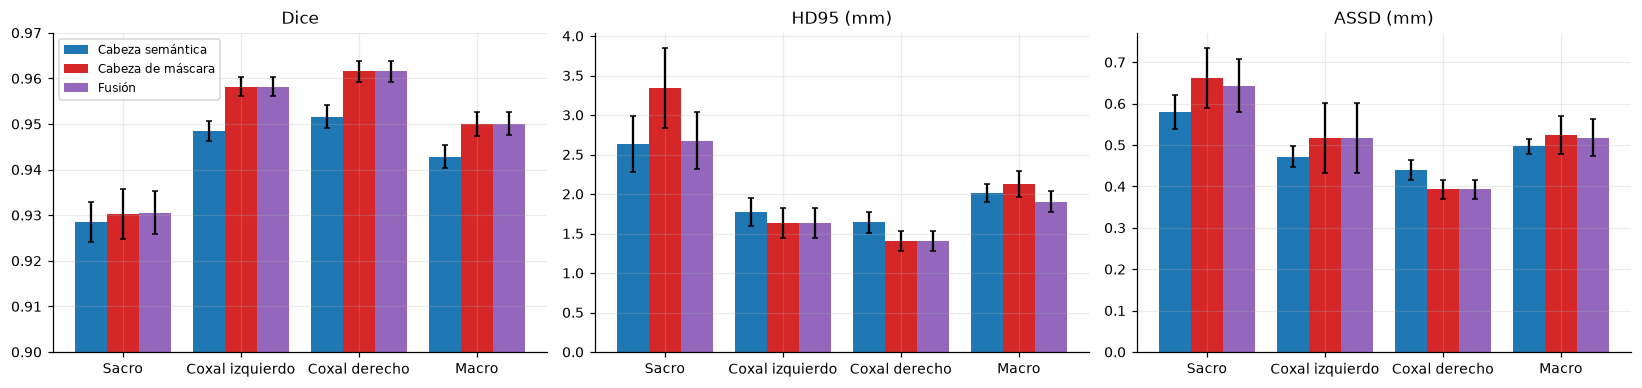

In [16]:
t = heads[heads.salida.isin(TRES)].groupby(["hueso", "salida"])[["dice", "iou", "hd95", "assd"]].mean().unstack("salida")
t = t.reindex(index=list(HUESOS)).rename(index=HUESOS)
t = t.reindex(columns=pd.MultiIndex.from_product([["dice", "iou", "hd95", "assd"], list(TRES)])).rename(
    columns={"dice": "Dice", "iou": "IoU", "hd95": "HD95 (mm)", "assd": "ASSD (mm)", **TRES})
display(t.round(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ancho, col3 = 0.27, {"semantica": "tab:blue", "mascara": "tab:red", FUS: "tab:purple"}
for a, (k, titulo) in zip(ax, (("dice", "Dice"), ("hd95", "HD95 (mm)"), ("assd", "ASSD (mm)"))):
    for i, (sal, nombre) in enumerate(TRES.items()):
        d = heads[heads.salida == sal]
        m = d.groupby("hueso")[k].mean().reindex(list(HUESOS))
        e = d.groupby("hueso")[k].std().reindex(list(HUESOS)) / np.sqrt(d.case_id.nunique())
        a.bar(np.arange(4) + (i - 1) * ancho, m, ancho, yerr=e, color=col3[sal], label=nombre, capsize=2)
    a.set_xticks(np.arange(4), [HUESOS[h].replace(" (3 huesos)", "") for h in HUESOS]); a.set_title(titulo)
    if k == "dice":
        a.set_ylim(0.90, 0.97)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 5.3 CT por CT

Cada punto es un CT de test: el valor de la fusión (eje y) frente al de cada cabeza (eje x). La tabla dice en cuántos CT
gana la fusión y la p de Wilcoxon pareado.

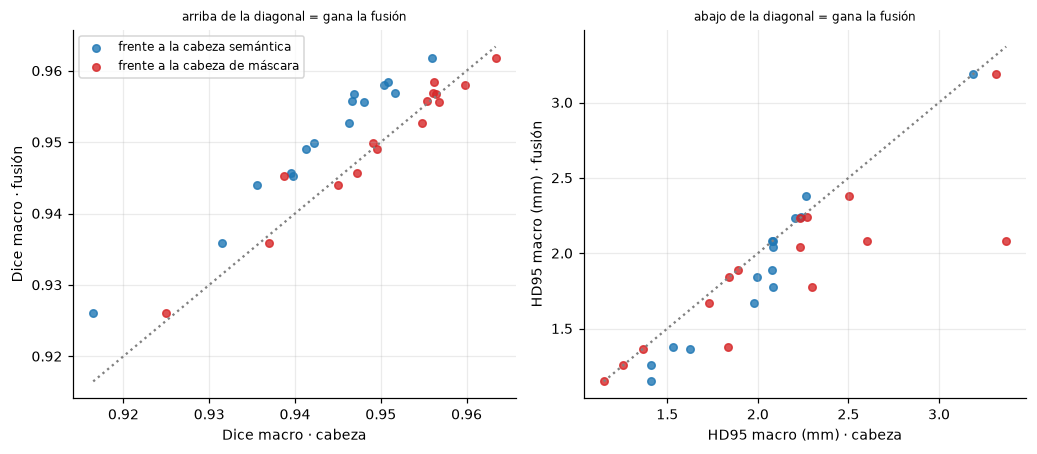

fusión  la otra CT donde gana la fusión  \
métrica         fusión frente a                                              
Dice macro      Cabeza semántica   0.9501   0.9429                15 de 15   
                Cabeza de máscara  0.9501   0.9500                 7 de 15   
HD95 macro (mm) Cabeza semántica   1.9046   2.0171                 9 de 15   
                Cabeza de máscara  1.9046   2.1264                 9 de 15   
ASSD macro (mm) Cabeza semántica   0.5180   0.4971                13 de 15   
                Cabeza de máscara  0.5180   0.5240                 7 de 15   

                                   p (Wilcoxon pareado)  
métrica         fusión frente a                          
Dice macro      Cabeza semántica                 0.0001  
                Cabeza de máscara                0.5245  
HD95 macro (mm) Cabeza semántica                 0.0121  
                Cabeza de máscara                0.0077  
ASSD macro (mm) Cabeza semántica                 0.0479  
                Cabeza de máscara                1.0000

In [17]:
piv = {k: heads[heads.hueso == "promedio"].pivot(index="case_id", columns="salida", values=k) for k in ("dice", "hd95", "assd")}
fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2))
for a, (k, titulo) in zip(ax, (("dice", "Dice macro"), ("hd95", "HD95 macro (mm)"))):
    for ref, color in (("semantica", "tab:blue"), ("mascara", "tab:red")):
        a.scatter(piv[k][ref], piv[k][FUS], s=24, color=color, alpha=0.8, label=f"frente a la {TRES[ref].lower()}")
    lo, hi = piv[k][list(TRES)].min().min(), piv[k][list(TRES)].max().max()
    a.plot([lo, hi], [lo, hi], color="grey", ls=":")
    a.set_xlabel(f"{titulo} · cabeza"); a.set_ylabel(f"{titulo} · fusión")
    a.set_title(f"{'arriba' if k == 'dice' else 'abajo'} de la diagonal = gana la fusión", fontsize=8)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
filas = []
for k, nombre in (("dice", "Dice macro"), ("hd95", "HD95 macro (mm)"), ("assd", "ASSD macro (mm)")):
    for ref in ("semantica", "mascara"):
        gana = (piv[k][FUS] > piv[k][ref]) if k == "dice" else (piv[k][FUS] < piv[k][ref])
        filas.append({"métrica": nombre, "fusión frente a": TRES[ref], "fusión": piv[k][FUS].mean(), "la otra": piv[k][ref].mean(),
                      "CT donde gana la fusión": f"{int(gana.sum())} de {len(gana)}",
                      "p (Wilcoxon pareado)": wilcoxon(piv[k][FUS], piv[k][ref]).pvalue})
pd.DataFrame(filas).set_index(["métrica", "fusión frente a"]).round(4)

### 5.4 Fragmentos conminutos y distancia de separación

Arriba: fracción de cada fragmento conminuto real que recupera cada salida, por tamaño. Abajo: error de la distancia de
separación (rúbrica 3.3) con cada salida, de `model3d evaluate`.

In [18]:
fr = R["CBAM"]["frags"]
fr = fr[~fr.principal].assign(cm3=lambda d: d.volumen_mm3 / 1000)
fr["tamaño"] = pd.cut(fr.cm3, [0, 10, 30, 1e9], labels=["< 10 cm³", "10-30 cm³", "> 30 cm³"])
rec = fr.groupby("tamaño", observed=True).agg(fragmentos=("cm3", "size"), **{TRES[k]: (f"recall_{k}", "mean") for k in TRES})
display(rec.round(3))
claves = {"Cabeza semántica": "separation_distance", "Cabeza de máscara": "separation_distance_mask", "Fusión": "separation_distance_fusion"}
filas = []
for split in ("val", "test"):
    for nombre, k in claves.items():
        d = metrics["splits"][split].get(k)
        if d:
            filas.append({"split": split, "salida": nombre, "fragmentos reales": d["fragments_gt"], "encontrados": d["matched"],
                          "unidos al principal": d["merged_with_main"], "error medio (mm)": d["mae_mm"],
                          "error medio en los > 2 mm": d["mae_mm_gt_2mm"]})
pd.DataFrame(filas).set_index(["split", "salida"]).round(2)

,fragmentos,Cabeza semántica,Cabeza de máscara,Fusión
tamaño,,,,
< 10 cm³,10,0.716,0.772,0.773
10-30 cm³,17,0.916,0.924,0.926
> 30 cm³,17,0.921,0.907,0.935


fragmentos reales  encontrados  unidos al principal  \
split salida                                                                   
val   Cabeza semántica                  37         0.97                 0.94   
      Cabeza de máscara                 37         0.97                 0.94   
      Fusión                            37         0.97                 0.94   
test  Cabeza semántica                  44         1.00                 0.93   
      Cabeza de máscara                 44         0.98                 0.91   
      Fusión                            44         0.98                 0.91   

                         error medio (mm)  error medio en los > 2 mm  
split salida                                                          
val   Cabeza semántica               4.17                      31.23  
      Cabeza de máscara              3.87                      28.53  
      Fusión                         3.87                      28.53  
test  Cabeza semántica               1.81                       9.67  
      Cabeza de máscara              1.78                      11.21  
      Fusión                         1.78                      11.21

### 5.5 Las tres salidas frente a la rúbrica

Como las mide `model3d evaluate` en test: la semántica contra la máscara real de 1,56 mm; la cabeza de máscara y la
fusión contra la de 0,78 mm.

In [19]:
tt = metrics["splits"]["test"]
ofi = {"Cabeza semántica (1,56 mm)": "segmentation_bones", "Cabeza de máscara (0,78 mm)": "segmentation_bones_mask",
       "Fusión (0,78 mm)": "segmentation_bones_fusion"}
pd.DataFrame({n: {"Dice macro": tt[k]["promedio"]["dice"], "IoU macro": tt[k]["promedio"]["iou"], "Dice sacro": tt[k]["sacro"]["dice"],
                  "Dice coxal izq.": tt[k]["coxal_izq"]["dice"], "Dice coxal der.": tt[k]["coxal_der"]["dice"],
                  "HD95 macro (mm)": tt[k]["promedio"]["hd95"], "ASSD macro (mm)": tt[k]["promedio"]["assd"]}
              for n, k in ofi.items() if k in tt}).T.assign(**{"cumple (Dice ≥ 0,85, IoU ≥ 0,70)": lambda d: np.where(
                  (d["Dice macro"] >= 0.85) & (d["IoU macro"] >= 0.70), "sí", "no")}).round(3)

,Dice macro,IoU macro,Dice sacro,Dice coxal izq.,Dice coxal der.,HD95 macro (mm),ASSD macro (mm),"cumple (Dice ≥ 0,85, IoU ≥ 0,70)"
"Cabeza semántica (1,56 mm)",0.952,0.909,0.937,0.958,0.961,2.119,0.535,sí
"Cabeza de máscara (0,78 mm)",0.950,0.905,0.930,0.958,0.962,2.126,0.524,sí
"Fusión (0,78 mm)",0.950,0.906,0.931,0.958,0.962,1.905,0.518,sí


### 5.6 Un ejemplo

El CT donde la cabeza de máscara pierde el ala del sacro (la caja no la cubre): máscara real y las tres salidas en el
mismo corte. Amarillo = error.

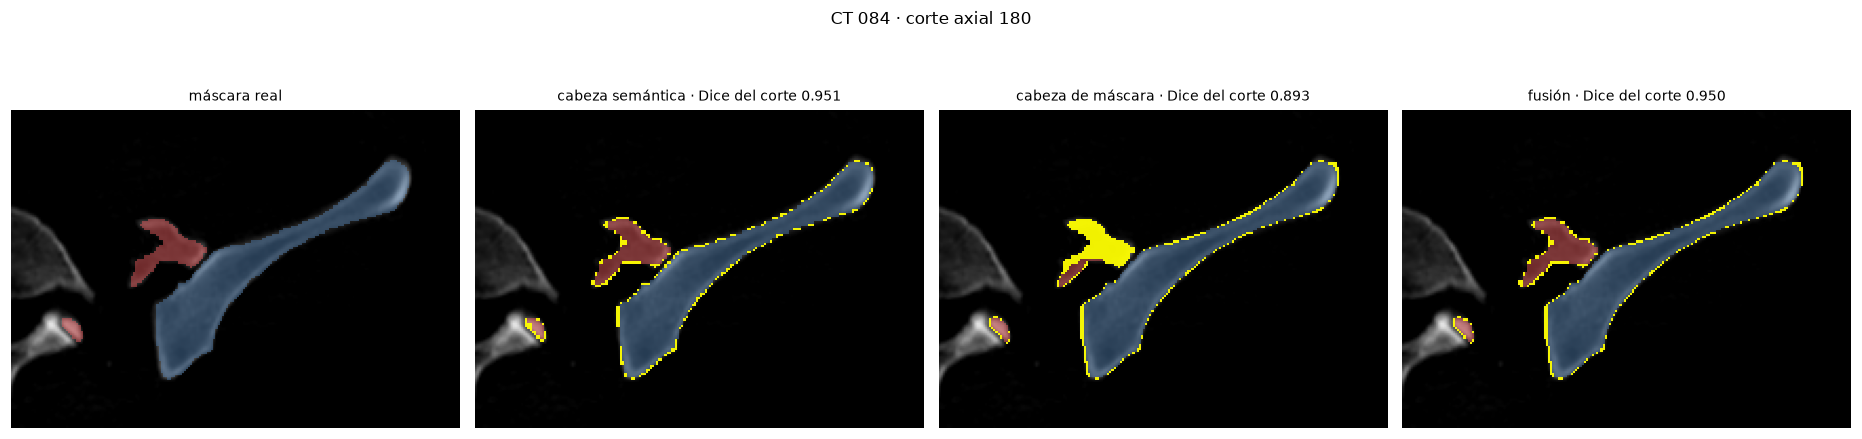

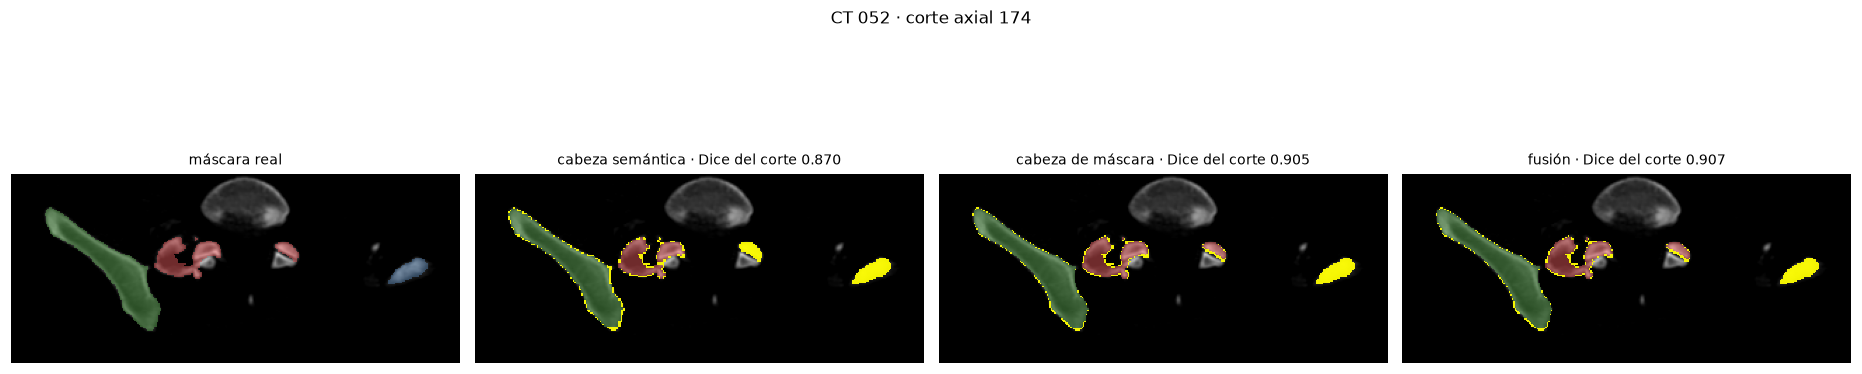

In [20]:
from src.models import model3d as M


def cargar_ejemplo_fusion(cid):
    e = cargar_ejemplo(RUNS["CBAM"], cid)
    z = np.load(EVAL / "examples_heads" / f"{cid}.npz")
    e["fus"] = M.fuse_heads(z["sem"], z["mask"])
    return e


def corte_dice(lab, gt):
    return 2 * ((lab == gt) & (gt > 0)).sum() / max((lab > 0).sum() + (gt > 0).sum(), 1)


for papel in ("gana_semantica", "gana_mascara"):
    e = cargar_ejemplo_fusion(PAPELES[papel])
    k = elegir_corte(e, papel)
    rec = recorte([e["gt"][k], e["sem"][k], e["mask"][k]])
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
    dibujar_mascara(axes[0], e["img"][k][rec], e["gt"][k][rec], None, "máscara real")
    for a, (nombre, vol) in zip(axes[1:], (("cabeza semántica", "sem"), ("cabeza de máscara", "mask"), ("fusión", "fus"))):
        dibujar_mascara(a, e["img"][k][rec], e[vol][k][rec], e["gt"][k][rec],
                        f"{nombre} · Dice del corte {corte_dice(e[vol][k], e['gt'][k]):.3f}")
    plt.suptitle(f"CT {e['cid']} · corte axial {k}", y=1.0); plt.tight_layout(); plt.show()

**La fusión es la mejor de las tres salidas, por poco:** iguala el Dice de la cabeza de máscara y tiene el mejor borde.

- **Frente a la semántica:** Dice macro 0,950 frente a 0,943, gana en los 15 CT (p = 0,0001); HD95 1,90 frente a
  2,02 mm.
- **Frente a la cabeza de máscara:** Dice igual (0,950); HD95 1,90 frente a 2,13 mm (p = 0,008), por el sacro (2,7
  frente a 3,3 mm). Donde la caja no cubre el ala del sacro, la fusión la toma de la semántica.
- **Fragmentos:** como la cabeza de máscara en los pequeños (0,77) y más que las dos en los grandes (0,94).
- **No cambia** la distancia de separación (1,78 mm; 11,2 mm en los fragmentos a más de 2 mm) ni los fragmentos sin
  caja.
- **Las tres cumplen la rúbrica.** En 5.5 la semántica se ve más alta (0,952) porque se mide contra la máscara de
  1,56 mm, que es menos exigente.

## 6. Las salidas de todas las cabezas en cuatro CT

Cuatro CT de test elegidos con el Dice macro de las dos cabezas de segmentación en la misma rejilla:

| Caso | Cómo se elige |
|---|---|
| **A las dos les va bien** | mayor Dice promedio de las dos salidas |
| **A las dos les va mal** | menor Dice promedio de las dos salidas |
| **Gana la cabeza de máscara** | mayor diferencia máscara − semántica |
| **Gana la cabeza semántica** | mayor diferencia semántica − máscara |

- **Fila de arriba (corte axial):** cajas reales (blanco discontinuo) y predichas (color del hueso y puntaje), máscara
  real, cabeza semántica y cabeza de máscara.
- **Fila de abajo:** Dice de cada salida corte por corte y el corte coronal.
- **Colores:** rojo sacro, azul coxal izquierdo, verde coxal derecho. **Amarillo = error.**

In [21]:
TITULOS = {"mejor": "A las dos cabezas les va bien", "peor": "A las dos cabezas les va mal",
           "gana_mascara": "Gana la cabeza de máscara", "gana_semantica": "Gana la cabeza semántica"}
filas = []
for papel, cid in PAPELES.items():
    hd = heads[(heads.case_id == cid) & (heads.hueso == "promedio")].set_index("salida")
    sac = heads[(heads.case_id == cid) & (heads.hueso == "sacro")].set_index("salida")
    c, rr = cases[cases.case_id == cid].iloc[0], rois[rois.case_id == cid]
    filas.append({"caso": TITULOS[papel], "CT": cid, "Dice semántica": hd.dice["semantica"], "Dice máscara": hd.dice["mascara"],
                  "Dice sacro (sem. / másc.)": f"{sac.dice['semantica']:.3f} / {sac.dice['mascara']:.3f}",
                  "HD95 semántica (mm)": hd.hd95["semantica"], "HD95 máscara (mm)": hd.hd95["mascara"],
                  "cajas": len(rr), "% cajas sin pareja": 100 * (rr.class_true < 0).mean(),
                  "clase correcta (%)": 100 * (rr[rr.class_true >= 0].class_true == rr[rr.class_true >= 0].class_pred).mean(),
                  "fragmentos conminutos": int(c.frag_gt)})
pd.DataFrame(filas).set_index("caso").round(3)

,CT,Dice semántica,Dice máscara,Dice sacro (sem. / másc.),HD95 semántica (mm),HD95 máscara (mm),cajas,% cajas sin pareja,clase correcta (%),fragmentos conminutos
caso,,,,,,,,,,
A las dos cabezas les va mal,034,0.916,0.925,0.882 / 0.881,2.238,2.269,355,10.141,100.0,2
A las dos cabezas les va bien,043,0.956,0.963,0.949 / 0.956,1.410,1.150,366,9.016,100.0,2
Gana la cabeza de máscara,052,0.947,0.956,0.935 / 0.942,1.994,1.840,343,6.122,100.0,4
Gana la cabeza semántica,084,0.940,0.939,0.912 / 0.893,2.078,3.371,367,11.989,100.0,5


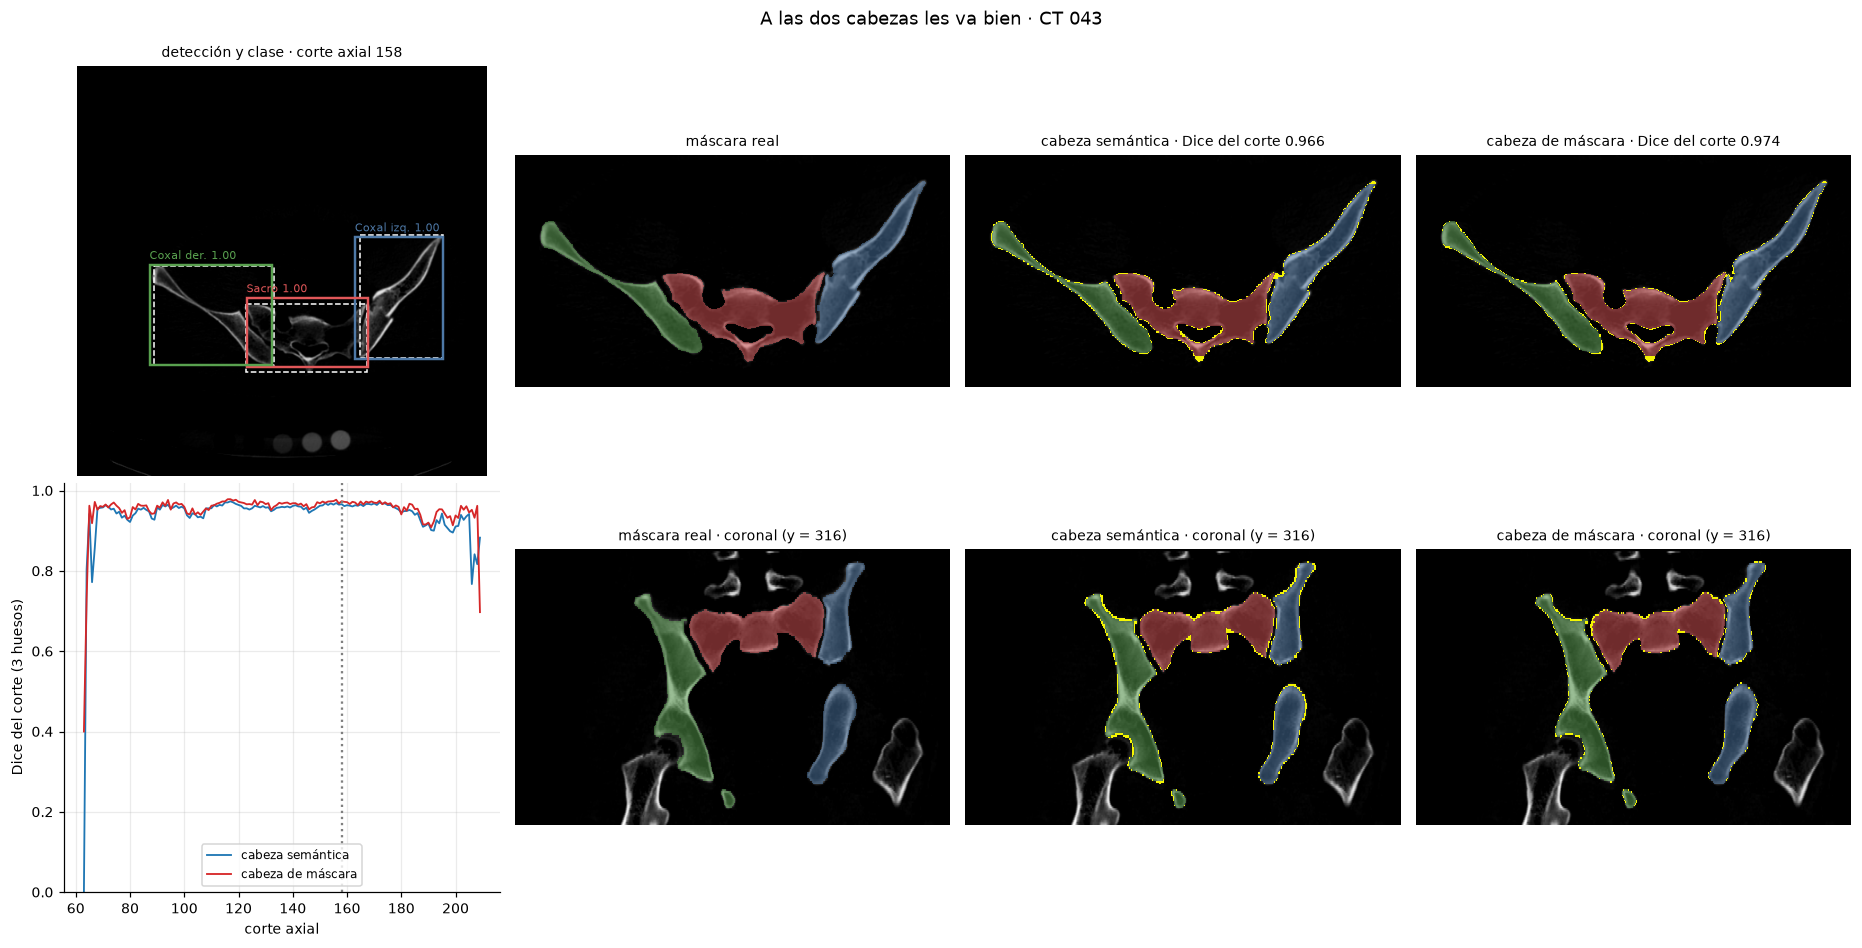

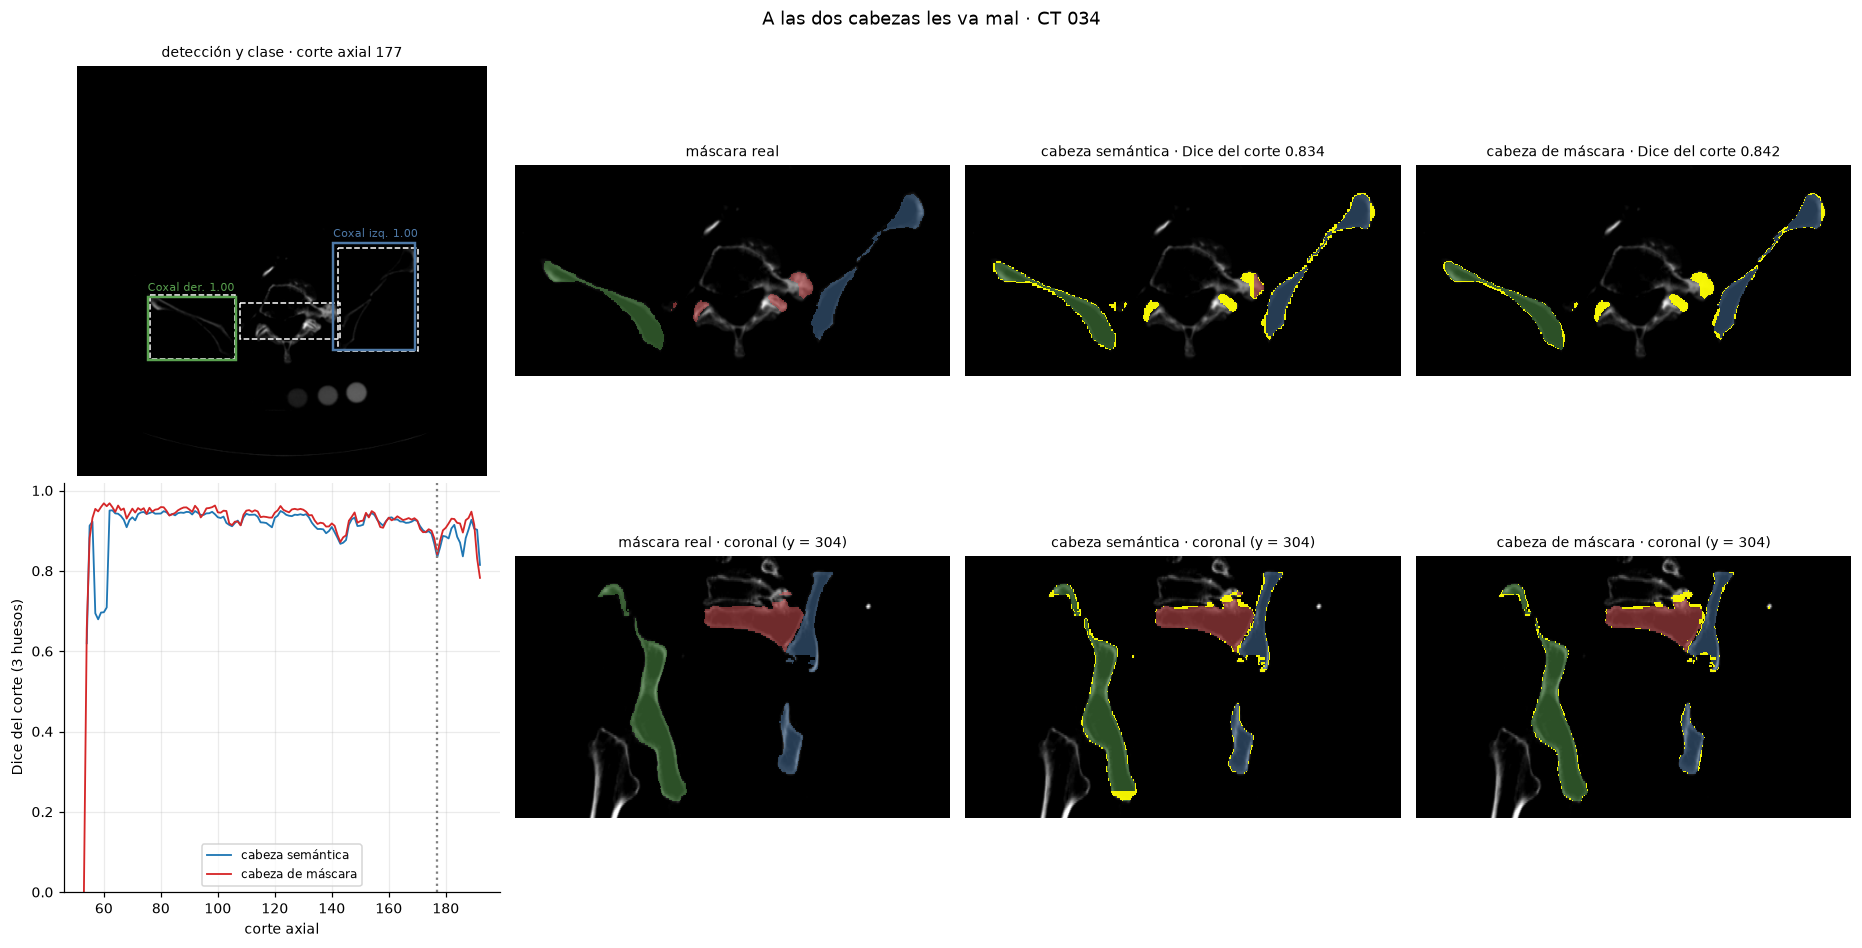

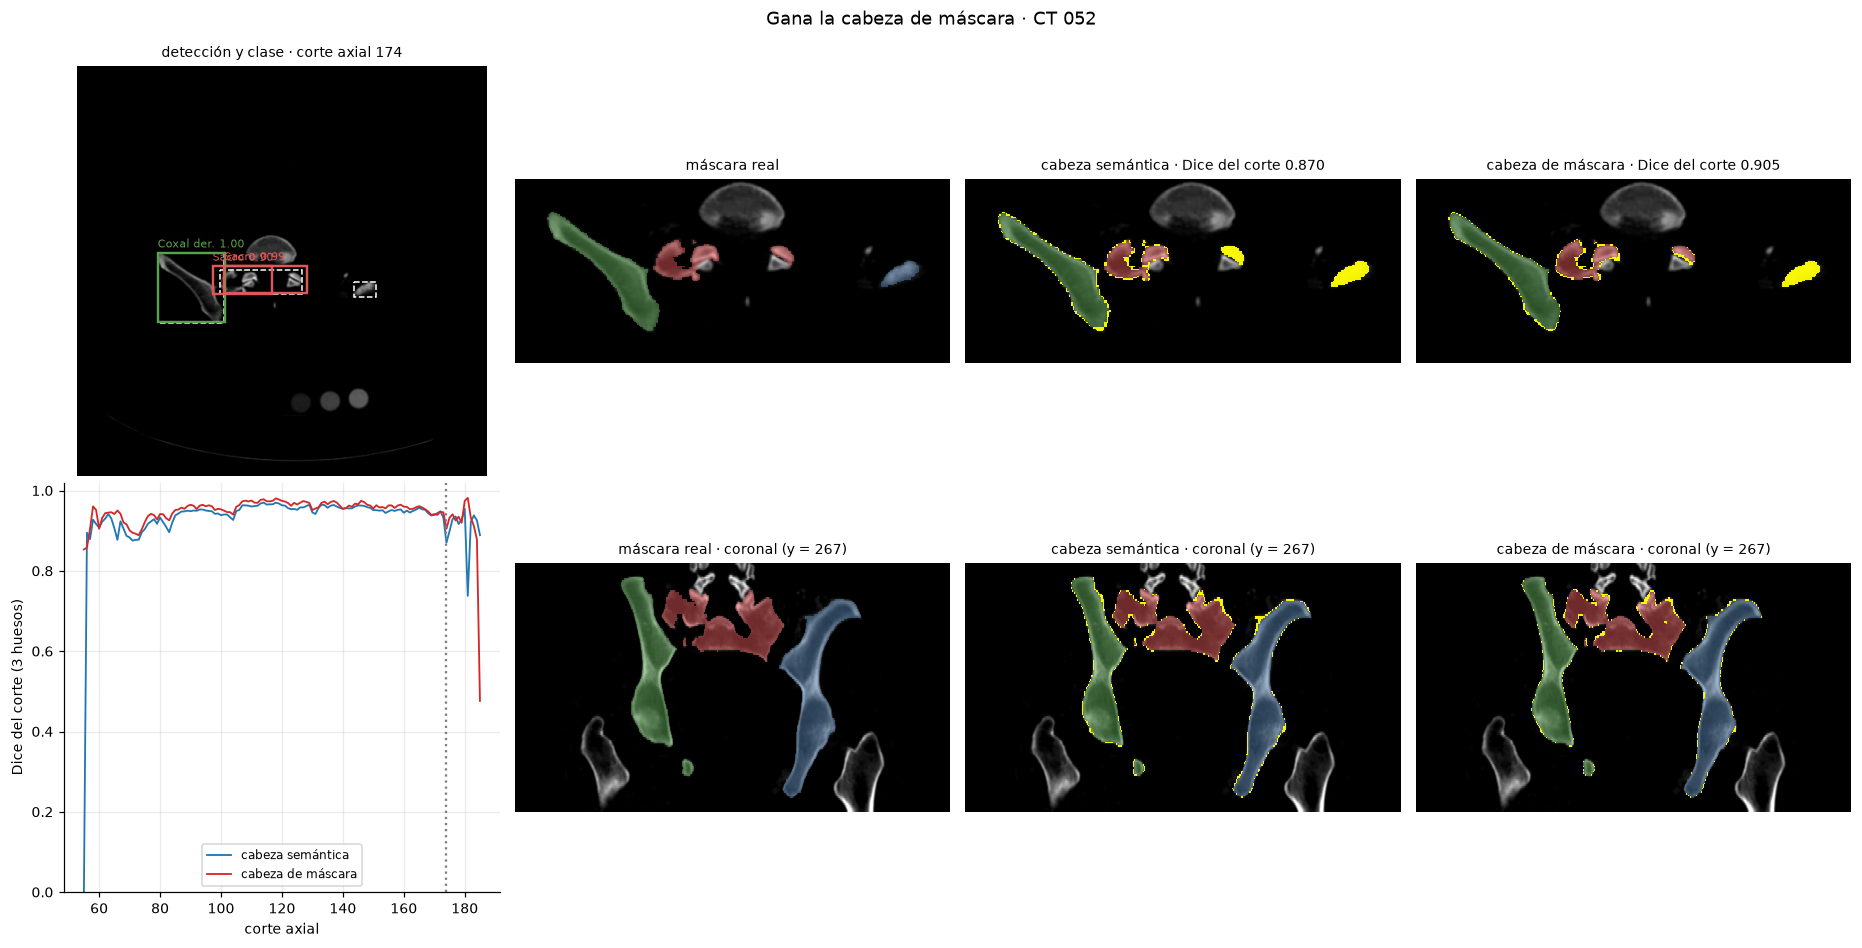

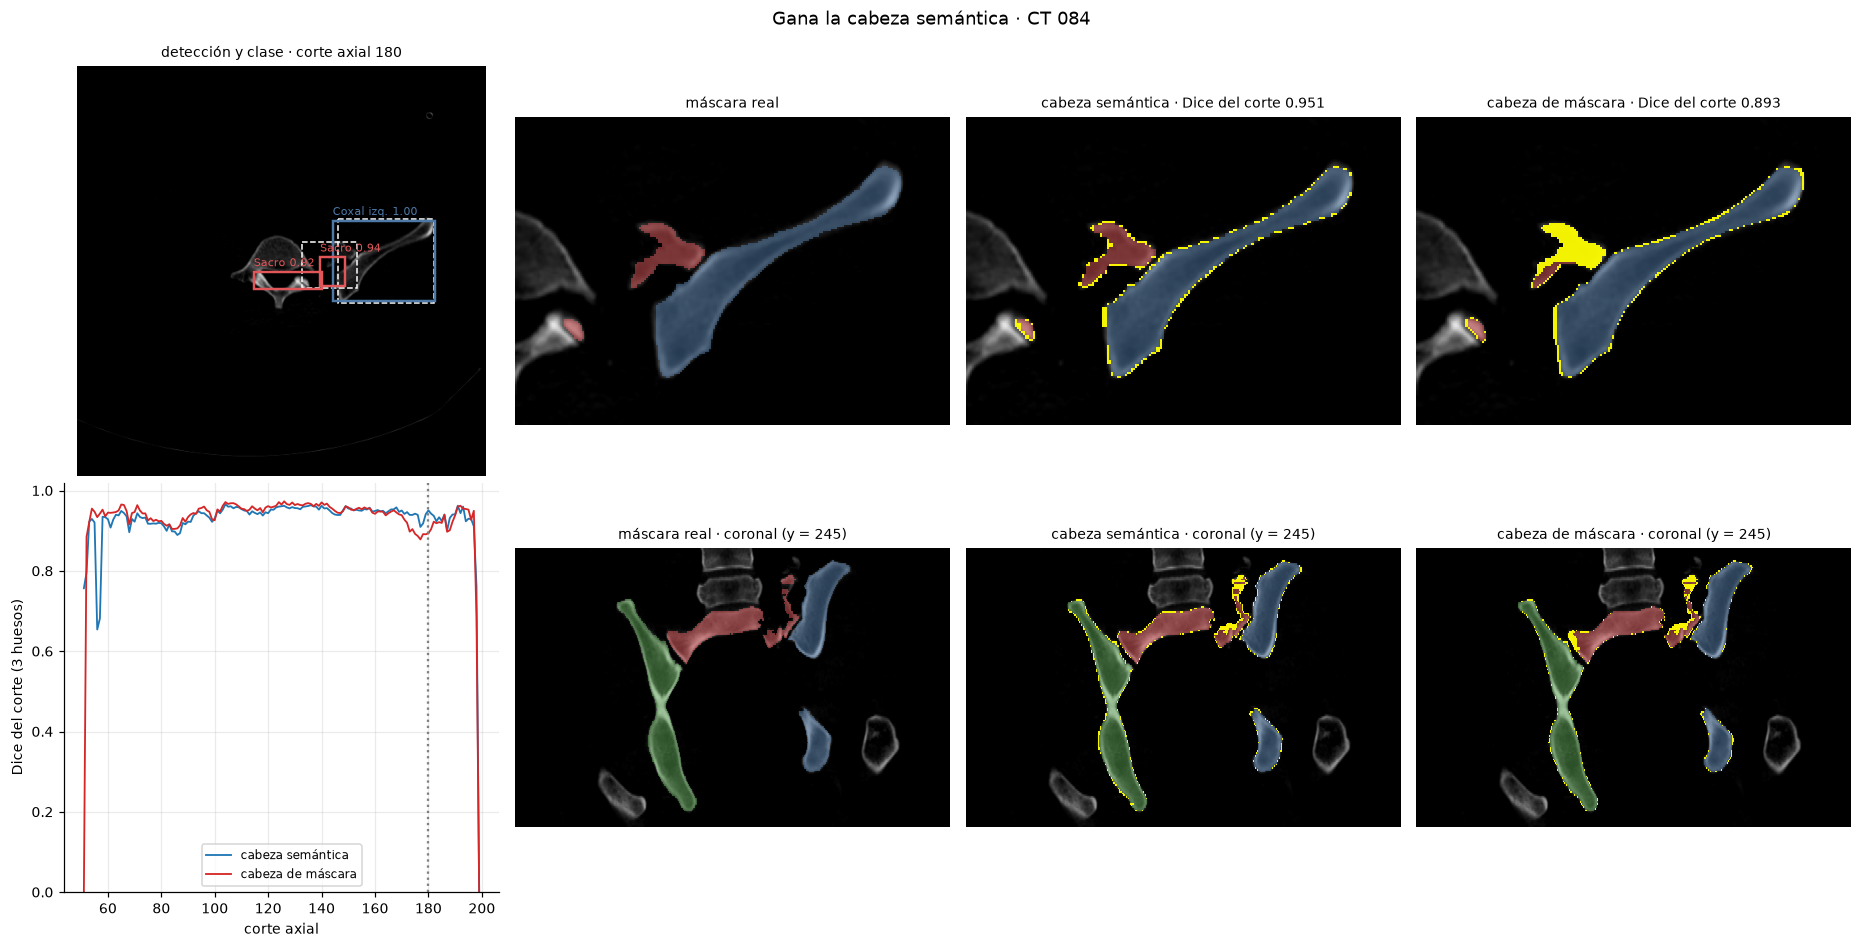

In [22]:
def figura_caso(e, papel, titulo, k=None):
    k = elegir_corte(e, papel) if k is None else k
    fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
    # Fila 1: corte axial
    dibujar_cajas(axes[0, 0], e, k)
    axes[0, 0].set_title(f"detección y clase · corte axial {k}", fontsize=9)
    rec = recorte([e["gt"][k], e["sem"][k], e["mask"][k]])
    img = e["img"][k][rec]
    dibujar_mascara(axes[0, 1], img, e["gt"][k][rec], None, "máscara real")
    dibujar_mascara(axes[0, 2], img, e["sem"][k][rec], e["gt"][k][rec], f"cabeza semántica · Dice del corte {e['sd_sem'][k]:.3f}")
    dibujar_mascara(axes[0, 3], img, e["mask"][k][rec], e["gt"][k][rec], f"cabeza de máscara · Dice del corte {e['sd_mask'][k]:.3f}")
    # Fila 2: Dice por corte y corte coronal (el de más hueso)
    a = axes[1, 0]
    zs = np.arange(len(e["sd_sem"]))
    a.plot(zs, e["sd_sem"], color="tab:blue", lw=1.2, label="cabeza semántica")
    a.plot(zs, e["sd_mask"], color="tab:red", lw=1.2, label="cabeza de máscara")
    a.axvline(k, color="grey", ls=":"); a.set_ylim(0, 1.02); a.set_xlabel("corte axial"); a.set_ylabel("Dice del corte (3 huesos)")
    a.legend(fontsize=8, loc="lower center")
    y = int((e["gt"] > 0).sum((0, 2)).argmax())
    cor = lambda vol: np.asarray(vol[:, y, :])[::-1]
    zz = np.nonzero((e["gt"] > 0).any((1, 2)))[0]
    rc = np.s_[max(len(e["gt"]) - zz.max() - 8, 0):len(e["gt"]) - zz.min() + 8, :]
    for ax, (nombre, vol) in zip(axes[1, 1:], (("máscara real", "gt"), ("cabeza semántica", "sem"), ("cabeza de máscara", "mask"))):
        dibujar_mascara(ax, cor(e["img"])[rc], cor(e[vol])[rc], None if vol == "gt" else cor(e["gt"])[rc],
                        f"{nombre} · coronal (y = {y})", aspect=F_HR)
    plt.suptitle(f"{titulo} · CT {e['cid']}", fontsize=12, y=0.995)
    plt.tight_layout(); plt.show()


for papel in ("mejor", "peor", "gana_mascara", "gana_semantica"):
    figura_caso(cargar_ejemplo(RUNS["CBAM"], PAPELES[papel]), papel, TITULOS[papel])

**Qué se ve en cada caso:**

- **CT 043, a las dos les va bien (0,956 y 0,963):** las cajas calzan con las reales y el error es una línea fina en el
  borde de los huesos.
- **CT 034, a las dos les va mal (0,916 y 0,925):** falla el sacro (0,88). En el corte mostrado no hay caja para el
  sacro y la semántica marca solo una parte.
- **CT 052, gana la cabeza de máscara (0,956 frente a 0,947):** sigue mejor los trozos pequeños del sacro. La punta del
  coxal izquierdo no tiene caja y ninguna salida la marca.
- **CT 084, gana la cabeza semántica (0,940 frente a 0,939):** las cajas del sacro no cubren el ala sacra; la cabeza de
  máscara la pierde y la semántica la marca.
- **En común:** los errores grandes de la cabeza de máscara vienen de la detección (caja ausente o mal puesta); los de
  la semántica son de borde y de los primeros y últimos cortes.

### 6.1 Galería: los cinco peores casos de test y el mejor

Los cinco CT de test con menor Dice de pelvis y el de mayor Dice, medidos sobre la máscara fusionada
(`scripts/inferir_casos_test.py` y `scripts/crear_galeria_errores_test.py`). De cada uno se muestra el corte axial con
más píxeles en desacuerdo: el CT, la máscara real con las cajas derivadas de las etiquetas, la predicción con las cajas
predichas y el mapa de errores.

**Mapa de errores:** verde = hueso bien identificado · rojo = hueso real que el modelo no segmentó · naranja = predicho
como hueso y no está en la máscara real · morado = marcado como otro hueso.

![Galería de casos](../docs/figuras/informe/figura_4_errores_cbam_5_peores_1_mejor.png)

| CT | Dice pelvis | Sacro | Coxal izq. | Coxal der. | Qué se ve y la causa probable |
|---|---|---|---|---|---|
| 034 | 0,934 | 0,884 | 0,943 | 0,951 | Naranja y morado en las dos articulaciones sacroilíacas: el modelo corre el límite entre el sacro y los coxales. Es el hueso menos denso de los seis (158 HU de media; el dataset promedia 356), con poco contraste en el borde. |
| 071 | 0,939 | 0,912 | 0,942 | 0,954 | Naranja dentro del sacro: el modelo rellena los agujeros sacros y los huecos del hueso. Píxel grueso (0,93 mm). |
| 073 | 0,946 | 0,925 | 0,959 | 0,948 | Rojo en el centro del sacro y naranja fino en los bordes: hueso poco denso (255 HU) con huecos que la máscara no sigue. |
| 048 | 0,947 | 0,934 | 0,961 | 0,942 | Casi todo verde; el error es una línea naranja en el borde de los huesos (la máscara queda un píxel más gruesa). |
| 039 | 0,951 | 0,939 | 0,950 | 0,961 | El coxal izquierdo tiene dos fragmentos en contacto, que el modelo segmenta como una sola región. Es el CT con más fragmentos (9) y el píxel más grueso (1,22 mm). |
| 043 | 0,963 | 0,952 | 0,966 | 0,968 | El mejor: errores de un píxel en los bordes y en la punta del coxal. |

- **El hueso que más baja es el sacro** (0,88 a 0,94 en los cinco peores); los coxales quedan por encima de 0,94.
- **Predomina el naranja sobre el rojo:** el modelo tiende a marcar de más (bordes gruesos y huecos rellenos) antes que
  a omitir hueso.
- **Causas que se repiten:** hueso de baja densidad, píxel grueso y el límite entre sacro y coxal.
- El peor caso de test queda por encima del objetivo (Dice ≥ 0,85).

## 7. Distancia de separación

Distancia mínima borde a borde de cada fragmento conminuto al fragmento principal de su hueso, en mm, en el **espacio
original del CT** (espaciado del header) con `distance_transform_edt`.
- **Real:** `src/metrics/distancias.py`. Un valor por cada fragmento etiquetado; el principal es el de más vóxeles. Los
  fragmentos que se tocan quedan a un paso de rejilla (~0,8 mm).
- **Predicha:** la máscara de cada hueso vuelve al espacio original; de sus componentes conexos, el más grande es el
  principal. Cada fragmento real se compara con el componente predicho que más se solapa con él: si es el principal, la
  red lo dejó unido a su hueso (distancia predicha 0).
- Con una máscara por hueso, la red no separa los fragmentos que se tocan; solo los que tienen una separación visible
  quedan como componentes aparte.

In [23]:
dist = pd.concat([pd.read_csv(EVAL / f"distances_{s}.csv", dtype={"case_id": str}) for s in ("val", "test")])
dist_m = pd.concat([pd.read_csv(EVAL / f"distances_mask_{s}.csv", dtype={"case_id": str}) for s in ("val", "test")])
resumen = pd.concat({"semántica": pd.DataFrame({s: metrics["splits"][s]["separation_distance"] for s in ("val", "test")}).T,
                     "máscara": pd.DataFrame({s: metrics["splits"][s]["separation_distance_mask"] for s in ("val", "test")}).T})
display(resumen.rename(columns={"fragments_gt": "fragmentos conminutos (reales)", "matched": "encontrados",
                                "merged_with_main": "unidos al principal", "mae_mm": "error medio (mm)",
                                "mean_gt_mm": "distancia real media (mm)", "gt_separated_gt_2mm": "reales a > 2 mm",
                                "mae_mm_gt_2mm": "error medio en los > 2 mm"}).round(2))
dist = dist.assign(dist_mascara_mm=dist_m.dist_pred_mm.values).rename(columns={"dist_pred_mm": "dist_semantica_mm"})
dist.sort_values("dist_gt_mm", ascending=False).head(12).round(1)

fragmentos conminutos (reales)  encontrados  \
semántica val                             37.0         0.97   
          test                            44.0         1.00   
máscara   val                             37.0         0.97   
          test                            44.0         0.98   

                unidos al principal  error medio (mm)  \
semántica val                  0.94              4.17   
          test                 0.93              1.81   
máscara   val                  0.94              3.87   
          test                 0.91              1.78   

                distancia real media (mm)  reales a > 2 mm  \
semántica val                        4.76              5.0   
          test                       1.99              5.0   
máscara   val                        4.76              5.0   
          test                       1.99              5.0   

                error medio en los > 2 mm  
semántica val                       31.23  
          test                       9.67  
máscara   val                       28.53  
          test                      11.21

,case_id,split,region,fragmento,n_voxels,dist_gt_mm,dist_semantica_mm,dist_mascara_mm
33,096,val,right_hipbone,23,21046,73.1,16.4,15.9
23,085,val,left_hipbone,12,22131,50.8,0.0,0.0
12,039,test,right_hipbone,23,1596,35.1,2.4,2.7
35,099,val,left_hipbone,12,20613,14.2,26.5,15.2
38,084,test,left_hipbone,14,1126,12.9,2.7,2.6
22,085,val,sacrum,2,469,7.5,NaN,NaN
10,055,val,right_hipbone,24,4166,5.1,0.0,0.0
27,052,test,right_hipbone,23,471,3.5,0.0,NaN
36,084,test,left_hipbone,12,16481,2.7,2.7,2.6
26,052,test,right_hipbone,22,9142,2.0,0.0,0.0


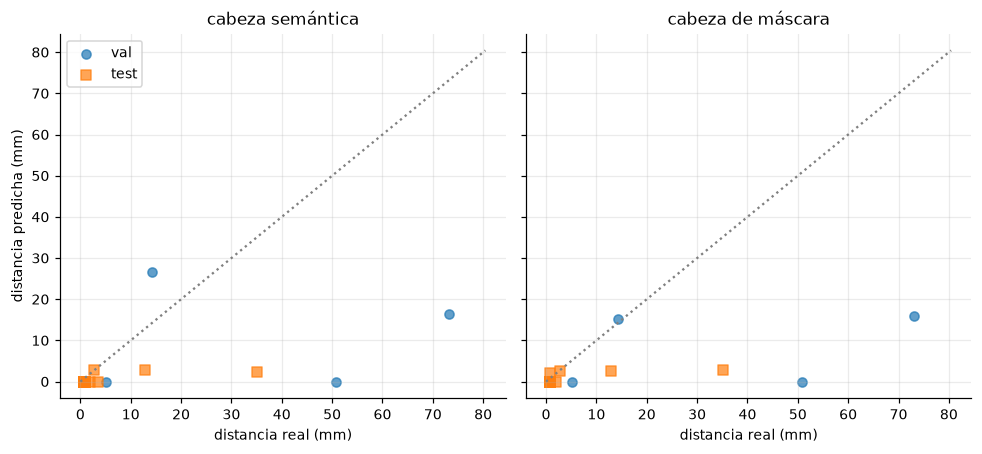

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for a, (col, nombre) in zip(ax, (("dist_semantica_mm", "cabeza semántica"), ("dist_mascara_mm", "cabeza de máscara"))):
    ok = dist.dropna(subset=[col])
    for split, mk in (("val", "o"), ("test", "s")):
        d = ok[ok.split == split]
        a.scatter(d.dist_gt_mm, d[col], marker=mk, alpha=0.7, label=split)
    lim = dist.dist_gt_mm.max() * 1.1
    a.plot([0, lim], [0, lim], color="grey", ls=":")
    a.set_xlabel("distancia real (mm)"); a.set_title(nombre)
ax[0].set_ylabel("distancia predicha (mm)"); ax[0].legend()
plt.tight_layout(); plt.show()

- **La mayoría de los fragmentos conminutos tocan su hueso** (44 en test; solo 5 están a más de 2 mm).
- **El modelo los deja unidos a su hueso** en el 93 % de los casos (semántica) y el 91 % (cabeza de máscara). Para los
  que se tocan es lo correcto: el error medio en test es de 1,8 mm.
- **Limitación:** en los separados más de 2 mm el error es de 10-11 mm en test. La red los une al principal, los parte
  en trozos o no los encuentra. Ni la cabeza de máscara ni la fusión lo cambian.

## 8. CBAM frente a SE

Los dos modelos son idénticos salvo el tipo de atención, en los mismos tres lugares (bloque 4 del encoder, P3 del
decoder y cabeza de detección):
- **CBAM:** atención de canal y espacial (qué canales y dónde mirar).
- **SE (squeeze-excitation):** solo atención de canal.

Mismos datos, mismas 140 épocas, mismo calendario de tasa de aprendizaje, mismos λ y misma semilla. **Hay un solo
entrenamiento de cada uno**, así que una diferencia pequeña puede ser ruido del entrenamiento y no efecto de la atención.

In [25]:
def fila_modelo(m, split):
    t = m["splits"][split]
    margin = m["refine_margin_from_val"]
    raw, sb, sm = t["detection"]["raw"]["all"], t["segmentation_bones"], t["segmentation_bones_mask"]
    return {"Detección · mAP@0,50": raw["mAP50"], "Detección · mAP@[0,50:0,95]": raw["mAP50_95"], "Detección · IoU": raw["mIoU"],
            "Detección + ajuste · mAP@[0,50:0,95]": t["detection"][f"m{margin}"]["all"]["mAP50_95"],
            "Semántica · Dice macro": sb["promedio"]["dice"], "Semántica · Dice sacro": sb["sacro"]["dice"],
            "Semántica · Dice coxal izq.": sb["coxal_izq"]["dice"], "Semántica · Dice coxal der.": sb["coxal_der"]["dice"],
            "Semántica · HD95 macro (mm)": sb["promedio"]["hd95"], "Semántica · ASSD macro (mm)": sb["promedio"]["assd"],
            "Máscara · Dice macro": sm["promedio"]["dice"], "Máscara · HD95 macro (mm)": sm["promedio"]["hd95"],
            "Máscara · ASSD macro (mm)": sm["promedio"]["assd"],
            "Clase por caja · F1 macro": t["classification_roi_end_to_end"]["macro_f1"],
            "Cajas sin pareja (%)": 100 * t["rois_unmatched_frac"],
            "Distancia de separación · error medio (mm)": t["separation_distance"]["mae_mm"]}


comp = pd.concat({s: pd.DataFrame({k: fila_modelo(R[k]["metrics"], s) for k in R}) for s in ("val", "test")}, axis=1)
for s in ("val", "test"):
    comp[(s, "CBAM − SE")] = comp[(s, "CBAM")] - comp[(s, "SE")]
comp = comp.sort_index(axis=1, level=0, sort_remaining=False).reindex(columns=["val", "test"], level=0)
comp.round(3)

val                    test  \
                                             CBAM     SE CBAM − SE   CBAM   
Detección · mAP@0,50                        0.929  0.919     0.010  0.938   
Detección · mAP@[0,50:0,95]                 0.707  0.707     0.000  0.686   
Detección · IoU                             0.875  0.874     0.000  0.861   
Detección + ajuste · mAP@[0,50:0,95]        0.814  0.806     0.008  0.816   
Semántica · Dice macro                      0.955  0.955     0.000  0.952   
Semántica · Dice sacro                      0.935  0.936    -0.001  0.937   
Semántica · Dice coxal izq.                 0.965  0.965     0.001  0.958   
Semántica · Dice coxal der.                 0.965  0.964     0.001  0.961   
Semántica · HD95 macro (mm)                 2.471  2.630    -0.159  2.119   
Semántica · ASSD macro (mm)                 0.527  0.550    -0.022  0.535   
Máscara · Dice macro                        0.952  0.953    -0.000  0.950   
Máscara · HD95 macro (mm)                   2.512  2.823    -0.311  2.126   
Máscara · ASSD macro (mm)                   0.493  0.522    -0.029  0.524   
Clase por caja · F1 macro                   1.000  1.000     0.000  1.000   
Cajas sin pareja (%)                        6.483  6.073     0.409  8.525   
Distancia de separación · error medio (mm)  4.170  4.113     0.057  1.813   

                                                             
                                               SE CBAM − SE  
Detección · mAP@0,50                        0.929     0.008  
Detección · mAP@[0,50:0,95]                 0.683     0.003  
Detección · IoU                             0.860     0.001  
Detección + ajuste · mAP@[0,50:0,95]        0.811     0.005  
Semántica · Dice macro                      0.951     0.001  
Semántica · Dice sacro                      0.936     0.002  
Semántica · Dice coxal izq.                 0.954     0.003  
Semántica · Dice coxal der.                 0.962    -0.001  
Semántica · HD95 macro (mm)                 6.875    -4.757  
Semántica · ASSD macro (mm)                 0.788    -0.253  
Máscara · Dice macro                        0.948     0.002  
Máscara · HD95 macro (mm)                   6.878    -4.752  
Máscara · ASSD macro (mm)                   0.804    -0.280  
Clase por caja · F1 macro                   1.000     0.000  
Cajas sin pareja (%)                        7.883     0.642  
Distancia de separación · error medio (mm)  1.808     0.004

In [26]:
from src.models import model3d as M

extra = {}
for k, run in RUNS.items():
    pesos = M.load_checkpoint(config.DETECTION_DIR / run / "best.pth")["model"]
    lat, hh = R[k]["metrics"]["latency"], R[k]["hist"]
    extra[k] = {"parámetros": sum(p.numel() for n, p in pesos.items() if not n.startswith("anchors_")),
                "mejor época": R[k]["metrics"]["epoch"], "puntaje de validación (best)": hh.val_score.max(),
                **{f"γ final · {c.removeprefix('gamma_')}": hh[c].iloc[-1] for c in hh.columns if c.startswith("gamma_")},
                **{f"latencia {d} (s por CT)": lat[d]["s_per_ct"] for d in lat}}
pd.DataFrame(extra).style.format(lambda x: f"{x:,.0f}" if abs(x) >= 100 else f"{x:.3f}")

,CBAM,SE
parámetros,"1,869,231","1,867,758"
mejor época,130,140
puntaje de validación (best),0.907,0.906
γ final · enc4,-0.299,-0.418
γ final · dec_p3,0.002,-0.126
γ final · head_axial,-0.125,-0.140
latencia cuda (s por CT),1.376,1.383
latencia cpu (s por CT),12.091,11.767


### Curvas de validación y γ de los dos modelos

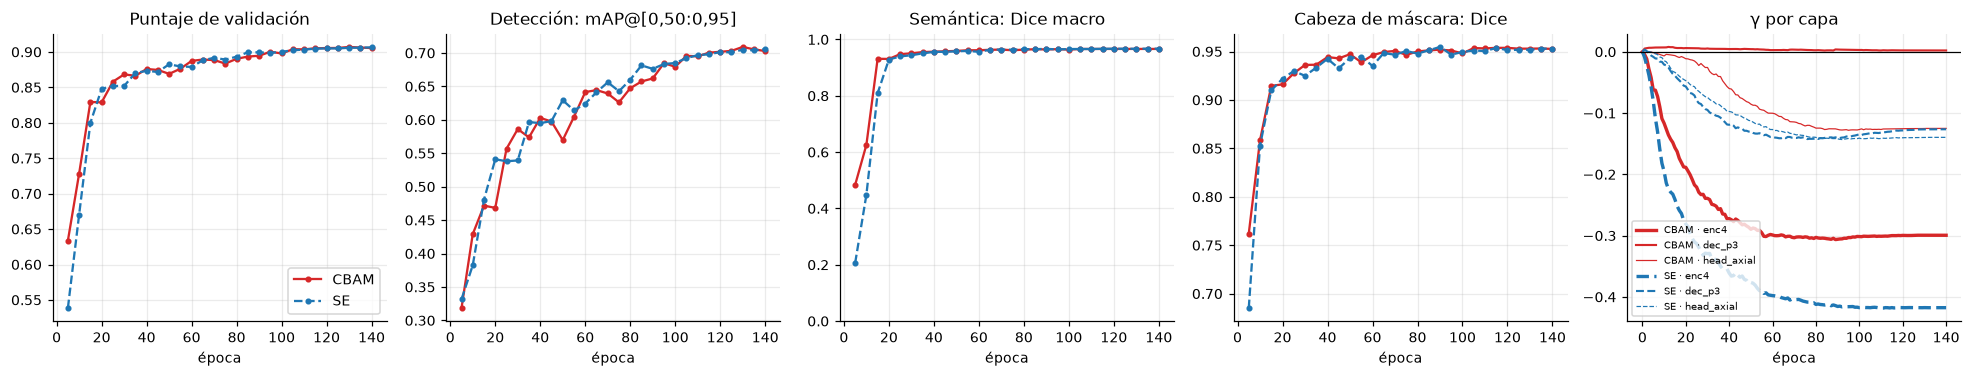

CBAM                                       SE               \
      val_dice_sacro val_dice_izq val_dice_der val_dice_sacro val_dice_izq   
epoch                                                                        
5              0.000        0.603        0.849          0.000        0.618   
10             0.000        0.937        0.941          0.002        0.929   
15             0.883        0.956        0.956          0.835        0.952   
20             0.896        0.949        0.948          0.898        0.949   
30             0.924        0.966        0.964          0.919        0.961   
140            0.954        0.973        0.972          0.956        0.973   

                    
      val_dice_der  
epoch               
5            0.000  
10           0.415  
15           0.642  
20           0.939  
30           0.952  
140          0.973

In [27]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.5))
estilo = {"CBAM": ("tab:red", "-"), "SE": ("tab:blue", "--")}
for a, (col, titulo) in zip(ax, (("val_score", "Puntaje de validación"), ("val_mAP50_95", "Detección: mAP@[0,50:0,95]"),
                                 ("val_dice_sem", "Semántica: Dice macro"), ("val_dice_mask", "Cabeza de máscara: Dice"))):
    for k, (color, ls) in estilo.items():
        d = R[k]["h"].dropna(subset=["val_score"])
        a.plot(d.epoch, d[col], "o", ls=ls, ms=3, color=color, label=k)
    a.set_title(titulo); a.set_xlabel("época")
ax[2].set_ylim(0, 1.02); ax[0].legend()
for k, (color, ls) in estilo.items():
    hh = R[k]["hist"]
    for c, lw in zip([c for c in hh.columns if c.startswith("gamma_")], (2.2, 1.4, 0.8)):
        ax[4].plot(hh.epoch + 1, hh[c], color=color, ls=ls, lw=lw, label=f"{k} · {c.removeprefix('gamma_')}")
ax[4].axhline(0, color="k", lw=0.8); ax[4].set_title("γ por capa"); ax[4].set_xlabel("época"); ax[4].legend(fontsize=6.5)
plt.tight_layout(); plt.show()
d = pd.concat({k: R[k]["h"].dropna(subset=["val_score"]).set_index("epoch")[["val_dice_sacro", "val_dice_izq", "val_dice_der"]]
               for k in R}, axis=1)
d.loc[[5, 10, 15, 20, 30, 140]].round(3)

### CT por CT (test)

Cada punto es un CT de test: el valor con CBAM (eje x) y con SE (eje y). Con 15 CT pareados se puede hacer una prueba de
Wilcoxon: dice si la diferencia es consistente entre CT, no si se debe a la atención (para eso harían falta varias
semillas por modelo).

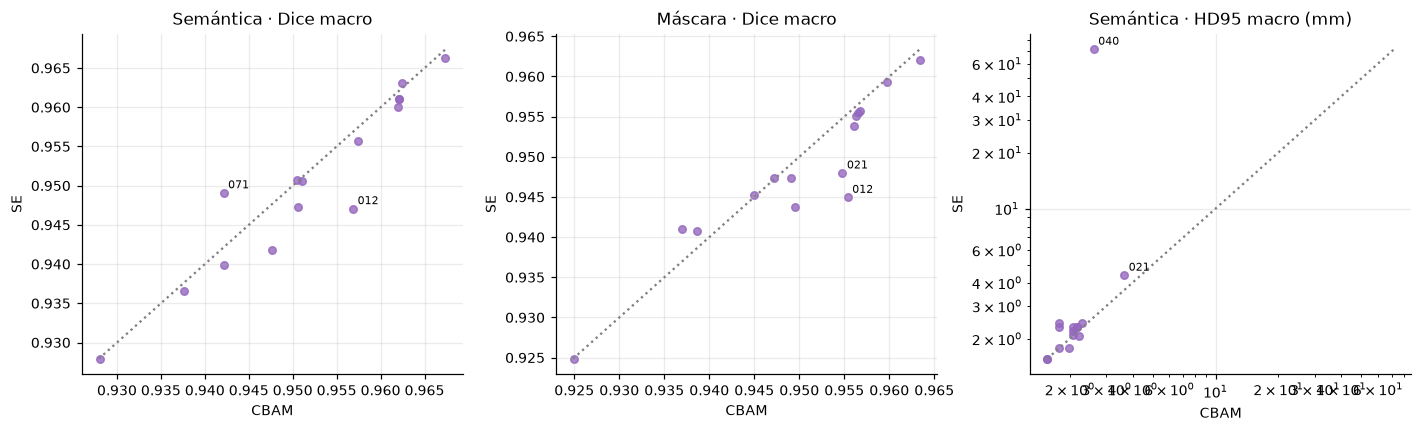

,CBAM,SE,mediana CBAM,mediana SE,CT donde gana CBAM,p (Wilcoxon pareado)
métrica,,,,,,
Semántica · Dice macro,0.9520,0.9505,0.9511,0.9506,12 de 15,0.0215
Máscara · Dice macro,0.9500,0.9483,0.9548,0.9474,11 de 15,0.0554
Semántica · HD95 macro (mm),2.1185,6.8753,2.0833,2.2991,9 de 15,0.0327
Semántica · ASSD macro (mm),0.5349,0.7880,0.5152,0.5352,12 de 15,0.0413
"Máscara · Dice macro (rejilla de 0,78 mm)",0.9500,0.9484,0.9548,0.9474,10 de 15,0.0946
"Semántica · Dice macro (rejilla de 0,78 mm)",0.9429,0.9409,0.9463,0.9403,11 de 15,0.0151


In [28]:
c1, c2 = (R[k]["cases"].set_index("case_id") for k in ("CBAM", "SE"))
hs = {k: R[k]["heads"][R[k]["heads"].hueso == "promedio"].pivot(index="case_id", columns="salida", values="dice") for k in R}
pares = {"Semántica · Dice macro": (c1.huesos_promedio_dice, c2.huesos_promedio_dice, True),
         "Máscara · Dice macro": (c1.mascara_promedio_dice, c2.mascara_promedio_dice, True),
         "Semántica · HD95 macro (mm)": (c1.huesos_promedio_hd95, c2.huesos_promedio_hd95, False),
         "Semántica · ASSD macro (mm)": (c1.huesos_promedio_assd, c2.huesos_promedio_assd, False),
         "Máscara · Dice macro (rejilla de 0,78 mm)": (hs["CBAM"].mascara, hs["SE"].mascara, True),
         "Semántica · Dice macro (rejilla de 0,78 mm)": (hs["CBAM"].semantica, hs["SE"].semantica, True)}
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, nombre in zip(ax, list(pares)[:3]):
    x, y, _ = pares[nombre]
    a.scatter(x, y, s=24, color="tab:purple", alpha=0.8)
    for cid in (y - x).abs().nlargest(2).index:
        a.annotate(cid, (x[cid], y[cid]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    a.plot([lo, hi], [lo, hi], color="grey", ls=":")
    if "HD95" in nombre:
        a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel("CBAM"); a.set_ylabel("SE"); a.set_title(nombre)
plt.tight_layout(); plt.show()
pd.DataFrame([{"métrica": n, "CBAM": x.mean(), "SE": y.mean(), "mediana CBAM": x.median(), "mediana SE": y.median(),
               "CT donde gana CBAM": f"{int(((x > y) if mayor else (x < y)).sum())} de {len(x)}",
               "p (Wilcoxon pareado)": wilcoxon(x, y).pvalue} for n, (x, y, mayor) in pares.items()]).set_index("métrica").round(4)

### El CT donde más se diferencian

El HD95 macro de SE en test (sección anterior) lo sube un solo CT. La figura muestra ese CT con las dos redes: el corte
axial donde la semántica de SE tiene más vóxeles de coxal izquierdo lejos (> 30 mm) del coxal izquierdo real.

CT 040 · Coxal izquierdo: vóxeles a más de 30 mm del hueso real → CBAM: 11 (0.0 cm³) | SE: 2237 (8.5 cm³) | HD95 del hueso: CBAM 1.6 mm, SE 209.6 mm


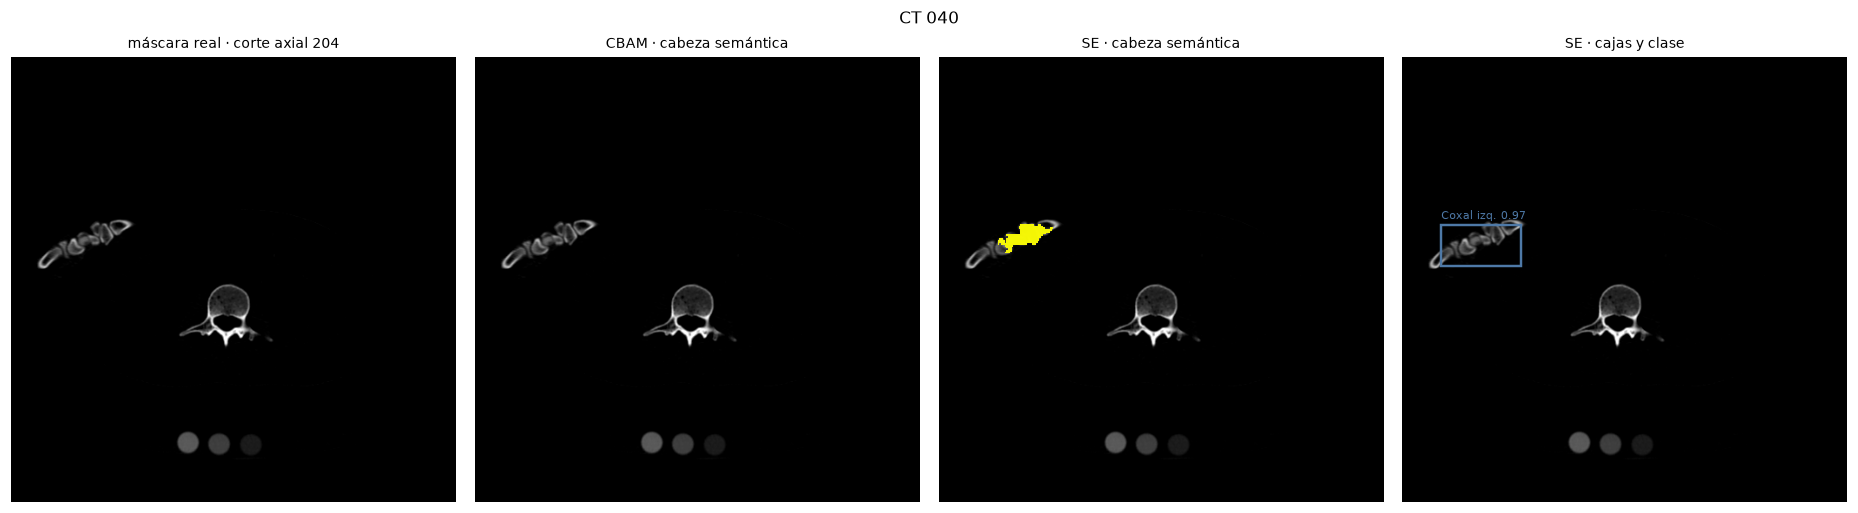

In [29]:
from scipy.ndimage import distance_transform_edt

cid = (c2.huesos_promedio_hd95 - c1.huesos_promedio_hd95).idxmax()
ej = {k: cargar_ejemplo(RUNS[k], cid) for k in R}
hueso = max((1, 2, 3), key=lambda b: c2.loc[cid, f"huesos_{list(HUESOS)[b - 1]}_hd95"])
gt_cubo = ej["SE"]["gt"][:, ::F_HR, ::F_HR]
lejos = {k: (ej[k]["sem"][:, ::F_HR, ::F_HR] == hueso) & (distance_transform_edt(gt_cubo != hueso) * config.VOXEL_MM > 30)
         for k in R}
k_ax = int(lejos["SE"].sum((1, 2)).argmax())
print(f"CT {cid} · {HUESOS[list(HUESOS)[hueso - 1]]}: vóxeles a más de 30 mm del hueso real → "
      + " | ".join(f"{k}: {int(lejos[k].sum())} ({lejos[k].sum() * config.VOXEL_MM ** 3 / 1000:.1f} cm³)" for k in R)
      + f" | HD95 del hueso: CBAM {c1.loc[cid, f'huesos_{list(HUESOS)[hueso - 1]}_hd95']:.1f} mm, SE "
        f"{c2.loc[cid, f'huesos_{list(HUESOS)[hueso - 1]}_hd95']:.1f} mm")
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
dibujar_mascara(axes[0], ej["SE"]["img"][k_ax], ej["SE"]["gt"][k_ax], None, f"máscara real · corte axial {k_ax}")
for a, k in zip(axes[1:3], R):
    dibujar_mascara(a, ej[k]["img"][k_ax], ej[k]["sem"][k_ax], ej[k]["gt"][k_ax], f"{k} · cabeza semántica")
dibujar_cajas(axes[3], ej["SE"], k_ax); axes[3].set_title("SE · cajas y clase", fontsize=9)
plt.suptitle(f"CT {cid}", y=1.0); plt.tight_layout(); plt.show()

**Empate, con una ventaja pequeña de CBAM en test.**

- **Validación:** iguales (puntaje 0,907 y 0,906; Dice semántico 0,955 los dos; mAP@[0,50:0,95] 0,707 los dos).
- **Test, Dice:** 0,952 frente a 0,951 en la semántica y 0,950 frente a 0,948 en la cabeza de máscara. CBAM gana en 12
  de 15 CT (p = 0,015).
- **Test, detección:** mAP@0,50 0,938 frente a 0,929; mAP@[0,50:0,95] 0,686 frente a 0,683.
- **Test, HD95:** 2,1 frente a 6,9 mm, por un solo CT (el 040): SE pone una caja de «coxal izquierdo» sobre una
  estructura fuera de la pelvis. Las medianas son parecidas (2,1 y 2,3 mm).
- **Costo:** mismos parámetros (1,87 M) y misma latencia.
- **γ:** las dos redes usan la atención del encoder (SE −0,42, CBAM −0,30) y la de la detección (−0,13 y −0,14). En el
  decoder, SE la usa (−0,13) y CBAM no (0,002).
- **Conclusión:** la parte espacial del CBAM no da una ganancia medible; lo que aporta es casi todo atención de canal.
  Se deja CBAM como modelo final. Con un solo entrenamiento por modelo, una diferencia de 0,002 de Dice puede ser
  ruido.

## 9. Comparación con SAM (baseline zero-shot)

SAM ViT-B sin entrenar: cada **caja axial predicha por el modelo** es el prompt de SAM en su corte, con el hueso que el
modelo predice dentro de ella. Las máscaras de SAM se apilan en un volumen por hueso y se comparan con la máscara real,
igual que las de la cabeza semántica (`scripts/run_sam_baseline_3d.py`). SAM no entra al pipeline.

In [30]:
SAM = config.RESULTS_DIR / "sam" / "sam3d_test_volumen.csv"
sam = pd.read_csv(SAM, dtype={"case_id": str})
t3 = sam.groupby("region")[["dice_sam", "dice_modelo", "iou_sam", "iou_modelo"]].mean()
t3 = t3.reindex(list(config.REGION_NAMES))
t3.loc["macro (3 huesos)"] = t3.mean()
t3.index = [{"sacrum": "Sacro", "left_hipbone": "Coxal izquierdo", "right_hipbone": "Coxal derecho"}.get(i, i) for i in t3.index]
t3.columns = ["Dice SAM", "Dice modelo", "IoU SAM", "IoU modelo"]
print("CT de test evaluados con SAM:", sam.case_id.nunique())
t3.round(3)

CT de test evaluados con SAM: 15


,Dice SAM,Dice modelo,IoU SAM,IoU modelo
Sacro,0.832,0.937,0.716,0.883
Coxal izquierdo,0.902,0.958,0.824,0.919
Coxal derecho,0.908,0.961,0.835,0.925
macro (3 huesos),0.881,0.952,0.791,0.909


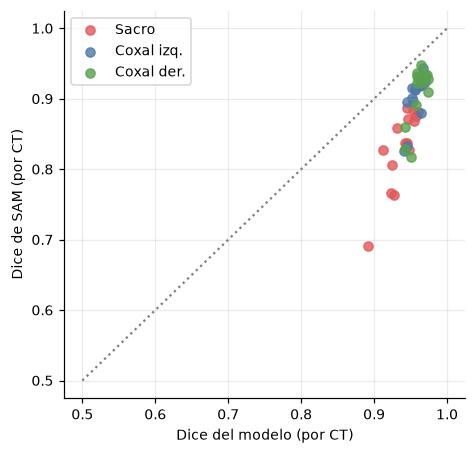

In [31]:
fig, ax = plt.subplots(figsize=(4.4, 4.2))
for region, nombre in (("sacrum", "Sacro"), ("left_hipbone", "Coxal izq."), ("right_hipbone", "Coxal der.")):
    d = sam[sam.region == region]
    ax.scatter(d.dice_modelo, d.dice_sam, label=nombre, color=config.REGION_COLORS[region], alpha=0.8)
ax.plot([0.5, 1], [0.5, 1], color="grey", ls=":")
ax.set_xlabel("Dice del modelo (por CT)"); ax.set_ylabel("Dice de SAM (por CT)"); ax.legend()
plt.tight_layout(); plt.show()

- **El modelo supera a SAM en los tres huesos** (Dice 3D macro 0,952 frente a 0,881; IoU 0,909 frente a 0,791).
- **Coxales:** SAM llega a 0,90-0,91 y el modelo a 0,96. Con una buena caja, un hueso grande y nítido es fácil incluso
  sin entrenar.
- **Sacro:** la mayor diferencia (0,832 frente a 0,937): forma compleja, y toca a L5 y a los coxales.
- **SAM recibe ayuda del modelo** (sus cajas y el hueso de cada una) y aun así queda por debajo.
- **Costo:** SAM tarda ~0,6 s por corte; el pipeline completo del modelo, 1,4 s por CT.

## 10. Latencia

Pipeline completo de inferencia sobre un CT ya preprocesado (red, detección axial, NMS, regiones, máscaras semánticas,
cabeza de máscara y clase por caja), en una GPU RTX 3060 y su CPU.

In [32]:
pd.concat({k: pd.DataFrame(R[k]["metrics"]["latency"]).T[["s_per_ct", "ms_per_slice"]] for k in R}).rename(
    columns={"s_per_ct": "segundos por CT", "ms_per_slice": "ms por corte axial"}).round(1)

segundos por CT  ms por corte axial
CBAM cuda              1.4                 5.4
     cpu              12.1                47.2
SE   cuda              1.4                 5.4
     cpu              11.8                46.0

## 11. Conclusiones

- **El modelo cumple todos los objetivos de la rúbrica en test:** detección (mAP@0,50 0,938, mAP@[0,50:0,95] 0,686,
  IoU 0,861), segmentación de los tres huesos (Dice macro 0,952, IoU 0,909) y clasificación por caja (F1 y AUC 1,0).
- **La cabeza de máscara** da una máscara por caja a 0,78 mm, algo mejor que la semántica en la misma rejilla (0,950
  frente a 0,943), sobre todo en coxales y fragmentos pequeños. Depende de que la detección dé una buena caja.
- **La fusión** de las dos salidas tiene el mejor borde (HD95 1,90 mm) y es la salida del comando de inferencia y del
  dashboard.
- **El sacro es el hueso más difícil** (Dice 0,937), pero supera 0,85 en todos los CT de test.
- **CBAM frente a SE:** empate en validación; en test CBAM es un poco mejor. La red no usa el CBAM del decoder (γ ≈ 0).
- **Distancia de separación:** 1,8 mm de error medio. Los fragmentos separados más de 2 mm salen mal (10-11 mm).
- **Inferencia:** `python -m src.models.model3d infer <ct>` acepta un CT con cualquier número de cortes, pero necesita
  la pelvis completa: con un recorte de solo parte de la pelvis falla.